# Western Loading Relief process examples (joint seams workshop, October 22, 2026)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pdockery/wscc9-illustrative-model/blob/main/workshop4_loading_relief.ipynb)

This notebook reproduces the four Western Loading Relief (WLR) examples. In each, two market engines clear independently on the WSCC 9-bus network and their superposed flow overloads line 6-7. The WLR process then assigns the relief to the markets' schedules. The slide checks are in `tests/test_slides_workshop4.py` and run with `python -m pytest tests -q -m slides`.

It follows the deck *Seams Workshop: Western Loading Relief process examples*, presented at the joint CAISO and SPP market seams workshop of October 22, 2026 (`caiso_spp_workshop_oct2026`). The excerpt is `sources/workshops/2026-10-22_loading_relief_examples.pdf`, and its page $n$ is page $51+n$ of the posted deck. A slide number below is the posted deck's page, which each slide prints in its footer. Example 1 is the first example of the August 18, 2026 workshop (`caiso_spp_workshop_aug2026`), on a fleet with one backstop unit added at each load bus.

WLR is the procedure of the proposed WEQ Western Interconnection Loading Relief Business Practice Standards, in the NAESB WEQ Executive Committee's recommendation as revised on October 22, 2025 (`naesb_weq_ecrec2025`, header and paragraphs 75 and 81). The recommendation links the standards text through NAESB's member login (`naesb_weq_ecrec2025`, paragraph 75). The proposal originated with the ECC Future State White Paper (`naesb_weq_ecrec2025`, paragraph 85; `eccetf_futurestate2024`). The rule here is this repository's reading of the recommendation's public summary and of that white paper.

The code runs on the modules in `lib/`. `wscc9_model` and `ieee9_network` build the case, `seams_engine` clears each market, `footprints` holds the market partition, `etag` writes the dispatch as e-tags and draws each tag's physical path, `atc` assigns the relief, `revenue_allocation` settles Market A's first clear, and `seam_views`, `wscc9_figures` and `nodal_plot` draw the figures.

In [1]:
#@title ▶ Run me first: Colab setup (installs packages, fetches the library)
# On Google Colab this installs the three packages Colab lacks and fetches the 14
# library modules into lib/. Run locally, it walks up from the working directory to
# the folder that holds lib/seams_engine.py and puts that lib/ on sys.path.
import pathlib
import subprocess
import sys

LIB_MODULES = (
    "atc", "bilateral", "etag", "footprints", "ieee9_network", "intertie",
    "lab_types", "nodal_plot", "revenue_allocation", "risk", "seam_views",
    "seams_engine", "wscc9_figures", "wscc9_model",
)

if "google.colab" in sys.modules:
    subprocess.run("pip install -q pypsa pandapower pycirclize", shell=True, check=True)
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main/lib"
    _lib = pathlib.Path.cwd() / "lib"
    _lib.mkdir(exist_ok=True)
    for _m in LIB_MODULES:
        subprocess.run(f"wget -q {_base}/{_m}.py -O {_lib / _m}.py", shell=True, check=True)
    print("Colab setup complete.")
else:
    _root = pathlib.Path.cwd()
    while not (_root / "lib" / "seams_engine.py").exists():
        if _root == _root.parent:
            raise FileNotFoundError(
                f"no lib/seams_engine.py in {pathlib.Path.cwd()} or any folder above it")
        _root = _root.parent
    _lib = _root / "lib"
    print("Local run: modules from the repository's lib/")
if str(_lib) not in sys.path:
    sys.path.insert(0, str(_lib))

Local run: modules from the repository's lib/


In [2]:
import copy
import dataclasses
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output
from matplotlib.patches import Patch

import atc
import footprints
import seam_views
import seams_engine
import wscc9_figures as figs
from etag import ETag, Segment, dispatch_tags, physical_path_figure
from nodal_plot import plot_combined_letter, plot_network_topology
from revenue_allocation import capacity_value_by_line, settlement_by_bus
from seams_engine import compute_ptdf, solve_engine_dispatch, susceptance_widths
from wscc9_model import (BUS_COLORS, CENTER_BUS, COORDS, RING_ORDER, build_network,
                         fleet_with_backstop, make_engine)

warnings.filterwarnings("ignore")
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("ieee9_network").setLevel(logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

# Every seam_views frame draws inline with no suptitle or panel title and writes no file.
seam_views.configure(strip_inline=True, save_enabled=False)
# Every dispatch ring draws each backstop at its capacity, faded where it is idle.
seams_engine.SHOW_IDLE_BACKSTOPS = True

## Formulation

Each market is a clearing engine that dispatches its own resources against its own load on the shared 9-bus network. It computes its own flow contribution on every line and enforces a limit only on the lines it activates. The WLR process measures the flow each scheduled transaction places on an overloaded line, assigns the relief the line needs to the transactions that load it, and states each market's share as its relief obligation. The examples write each market's dispatch as e-tags, so the process reads the markets' dispatch through their tags.

**Nomenclature.** Sets are script capitals, an element is the matching lower-case letter, and upper case names a market engine.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$, $n$ | `pt.buses` | the set of buses; $n\in\mathcal N$ |
| $\mathcal M$, $m$ | `pt.lines` | the network line set, every line of the shared network; $m\in\mathcal M$, and line 6-7 is `line_4` |
| $SF_{n,m}$ | `pt.ptdf[m, n]`, `SF` | shift factor of bus $n$ on line $m$, with bus 1 the reference bus; the array is indexed line first, and `SF` holds line 6-7's column |
| $\bar F_m$ | `pt.s_nom` | rating of line $m$ |
| $\mathcal E$, $M$, $M'$ | `make_engine` | the set of market engines, $\mathcal E=\{A,B\}$; $M'$ is the market other than $M$ |
| $\mathcal R^M$, $i$ | `eng.gens` | market $M$'s resources, the backstops at its load buses included |
| $n(i)$ | `eng.gens[i]["bus"]` | the bus of resource $i$ |
| $c_i$, $\bar g_i$ | `eng.gens[i]["cost"]`, `eng.gens[i]["p_nom"]` | resource $i$'s offer price and capacity |
| $g_i$, $g^M_{(n)}$ | `res.dispatch`, `res.gen_by_bus` | dispatch of resource $i$; market $M$'s dispatch summed at bus $n$ |
| $d^M_n$ | `eng.loads` | market $M$'s load at bus $n$ |
| $\mathcal M^M_{\mathrm{mon}}$ | `MONITORED_LINES` | market $M$'s monitored lines, the subset of $\mathcal M$ it models and watches |
| $\mathcal M^M_{\mathrm{act}}$ | `ACTIVATED_LINES`, `eng.activated_lines` | market $M$'s activated set, the monitored lines whose limits it enforces; $\mathcal M^M_{\mathrm{act}}\subseteq\mathcal M^M_{\mathrm{mon}}$ |
| $\hat\lambda^M_a$ | `res.energy_price` | market $M$'s energy price, the dual of its one area balance |
| $\lambda^M_n$ | `res.lmp` | market $M$'s nodal LMP at bus $n$ |
| $\mu^M_m$ | `res.line_dual` | market $M$'s signed dual of line $m$'s limit; printed values show $\lvert\mu^M_m\rvert$ |
| $F^M_m$ | `res.flow_own` | market $M$'s flow contribution on line $m$ |
| $\widehat F^{M'}_m$ | `flow_offsets=` | the flow of market $M'$ on line $m$ that market $M$ carries as a fixed input |
| $F^s_m$ | `superposed`, `combined_views` (`F_phys`) | the superposed flow, the flow line $m$ carries |
| $C^M$ | `res.total_cost` | market $M$'s production cost |
| $R^M$ | `settlement_by_bus`, `capacity_value_by_line` | market $M$'s congestion rent |
| $\Delta g_i$ | `price_walk`, `line_walk` | the redispatch of resource $i$ in a production-cost walk |
| $\mathcal K$, $k$; $\mathcal K^M$ | `etag.ETag` | the set of e-tags and an element; market $M$'s tags |
| $\mathrm{src}(k)$, $\mathrm{snk}(k)$, $\mathrm{MW}_k$ | `tag.source`, `tag.sink`, `tag.mw` | tag $k$'s source bus, sink bus and energy profile |
| $p_k$ | `Segment.priority`, `TAG_PRIORITY` | tag $k$'s NERC transmission priority code, read as a level from 0 to 7 |
| $\mathrm{TDF}_{k,m}$, $I_{k,m}$ | `ledger["TDF"]`, `ledger["impact"]` | tag $k$'s transfer distribution factor on line $m$, and its impact |
| $\operatorname{sgn}F^s_m$ | `ledger.attrs["direction"]` | the loading direction of line $m$, the sign of the superposed flow |
| $\Delta F_m$ | `ledger.attrs["R"]` | the relief requirement on line $m$ |
| $\theta$ | `WLR_THRESHOLD` | the eligibility threshold, 0.05 |
| $\mathcal K^e_m$, $p^*$ | `ledger["eligible"]`, `ledger.attrs["last_bucket"]` | the eligible tags on line $m$, and the last priority level the assignment reaches |
| $r_k$, $x_k$ | `ledger["relief"]`, `ledger["instructed MW"]` | tag $k$'s relief, in MW of flow on line $m$, and its curtailment, in MW of energy |
| $\rho^M_m$ | `obligations` | market $M$'s relief obligation on line $m$ |
| $u(k)$, $\beta(n)$ | `UNIT_OF`, `backstop_<n>` | the unit that sources tag $k$; the backstop unit at load bus $n$ |
| $\hat g^A_n$, $\hat d^A_n$ | `G_UN_A`, `D_UN_A` | Market A's untagged generation and untagged load at bus $n$ (Example 3) |
| $\mathrm{LSF}^A_m$ | `GTL_A["lsf"]` | Market A's load-weighted shift factor on line $m$ |
| $I^{\mathrm{GTL},A}_m$, $\rho^{\mathrm{GTL},A}_m$ | `GTL_A`, `RHO_GTL_A` | the impact of Market A's untagged generation-to-load, and its obligation |
| $I^{\mathrm{gen}}_{n,m}$, $r^{\mathrm{gen}}_n$, $x^{\mathrm{gen}}_n$ | `GEN_A` | Market A's untagged generation at bus $n$: its contribution to line $m$, its share of the GTL obligation, and its instruction |
| $F^M_m(0)$, $\bar F^M_m$ | `F0`, `LIM_A`, `LIM_B` | market $M$'s flow contribution in the blind clear, and its market flow limit |

**The program.** Market $M$ clears

$$\min_{0\le g_i\le\bar g_i}\ C^M=\sum_{i\in\mathcal R^M}c_i\,g_i\quad\text{s.t.}\quad\sum_{i\in\mathcal R^M}g_i=\sum_{n\in\mathcal N}d^M_n\ \ [\hat\lambda^M_a],\qquad -\bar F_m\le F^M_m+\widehat F^{M'}_m\le\bar F_m\ \ [\mu^M_m],\ \ m\in\mathcal M^M_{\mathrm{act}}. \qquad (1)$$

*In words.* Market $M$ minimizes its production cost $C^M$, the offer price $c_i$ times the dispatch $g_i$ summed over its resources $\mathcal R^M$, with each dispatch within its capacity $\bar g_i$, subject to two constraint families: its dispatch equals the load it serves (dual $\hat\lambda^M_a$, its energy price); and on each activated line $m\in\mathcal M^M_{\mathrm{act}}$, its own flow contribution $F^M_m$ plus the flow of the other market it carries as an input, $\widehat F^{M'}_m$, stays within the rating $\bar F_m$ (dual $\mu^M_m$, that line's signed shadow price).

Each market holds one balancing authority area, so (1) carries one area balance. The blind clears of Example 1 set $\widehat F^{M'}=0$, and Market A's redispatch sets $\widehat F^{B}$ to Market B's realized flow. Example 4 sets $\widehat F^{M'}=0$ and gives line 6-7 each market's limit (16) as its rating. The engine also carries load shedding at the shed price, and no clear in this notebook sheds.

**The flow contribution and the superposed flow.**

$$F^M_m=\sum_{n\in\mathcal N}SF_{n,m}\big(g^M_{(n)}-d^M_n\big),\qquad F^s_m=\sum_{M\in\mathcal E}F^M_m\qquad(m\in\mathcal M). \qquad (2)$$

*In words.* Market $M$'s flow contribution $F^M_m$ on line $m$ is each bus's shift factor $SF_{n,m}$ times market $M$'s net injection there, its dispatch at the bus $g^M_{(n)}$ less its load $d^M_n$, summed over every bus $n\in\mathcal N$. The superposed flow $F^s_m$ is the sum of the markets' flow contributions over the engine set $\mathcal E$.

Each market holds $\lvert F^M_m+\widehat F^{M'}_m\rvert$ within the rating on its own activated lines only. With $\widehat F^{M'}=0$ that does not hold $\lvert F^s_m\rvert$ within the rating, and Example 1 shows it on line 6-7.

**The nodal price.**

$$\lambda^M_n=\hat\lambda^M_a+\sum_{m\in\mathcal M^M_{\mathrm{act}}}SF_{n,m}\,\mu^M_m. \qquad (3)$$

*In words.* Market $M$'s nodal LMP $\lambda^M_n$ at bus $n$ is its energy price $\hat\lambda^M_a$ plus, summed over its activated set, each line's shift factor $SF_{n,m}$ from that bus times the line's signed dual $\mu^M_m$.

The energy price is the price at the reference bus, bus 1, whose shift factors are zero.

The EDAM technical description writes the dual with a minus sign in the LMP (`caiso_edam_techdesc`, p. 26), so its dual is the negative of the signed $\mu^M_m$ of (3). Its LMP also divides the energy price by a loss penalty factor and adds a greenhouse-gas price in a GHG regulation area. Program (1) is lossless, so the loss penalty factor is 1, and it carries no greenhouse-gas term.

**A price as a production-cost change.** Line $m$ binds, and resources $i$ and $j$ are interior, at buses $n(i)$ and $n(j)$.

$$\Delta g_i+\Delta g_j=1,\ \ SF_{n(i),m}\Delta g_i+SF_{n(j),m}\Delta g_j=SF_{n,m}\ \Rightarrow\ \lambda^M_n=c_i\Delta g_i+c_j\Delta g_j;\qquad \Delta g_i+\Delta g_j=0,\ \ SF_{n(i),m}\Delta g_i+SF_{n(j),m}\Delta g_j=\operatorname{sgn}\mu^M_m\ \Rightarrow\ \lvert\mu^M_m\rvert=c_i\Delta g_i+c_j\Delta g_j. \qquad (4)$$

*In words.* One more MW of load at bus $n$ moves the pair by redispatches $\Delta g_i$ and $\Delta g_j$ that sum to one MW and hold line $m$'s flow, and the LMP $\lambda^M_n$ is the pair's cost, $c_i\Delta g_i+c_j\Delta g_j$. One MW off line $m$ moves the pair by redispatches that sum to zero and lower the line's flow by one MW in its loading direction, and the absolute dual $\lvert\mu^M_m\rvert$ is the pair's cost.

**The congestion rent.**

$$R^M=\sum_{m\in\mathcal M^M_{\mathrm{act}}}\lvert\mu^M_m\rvert\,\lvert F^M_m\rvert=\sum_{n\in\mathcal N}\lambda^M_n d^M_n-\sum_{n\in\mathcal N}\lambda^M_n g^M_{(n)}. \qquad (5)$$

*In words.* Market $M$'s congestion rent $R^M$ is the absolute dual $\lvert\mu^M_m\rvert$ times the absolute own flow $\lvert F^M_m\rvert$, summed over its activated lines. It equals what market $M$'s load pays, $\sum_n\lambda^M_n d^M_n$, less what its generation is paid, $\sum_n\lambda^M_n g^M_{(n)}$.

The anchor is the base clearing, one engine over both footprints that enforces both activated sets. It binds line 6-7 at 40 MW with a dual of \$20.10/MWh and a congestion rent of \$804.1/h. Market A's clear binds line 6-7 at 40 MW with the base clearing's marginal pair, the bus-2 and bus-3 units, so it reproduces that clearing's $\lvert\mu^A_m\rvert$ of \$20.10/MWh and $R^A$ of \$804.1/h. The slide 57 section runs the base clearing and prints all three numbers beside Market A's.

**The cost of an input.**

$$C^A\big(\widehat F^{B}\big)-C^A(0)=\lvert\mu^A_m\rvert\,\widehat F^{B}_m. \qquad (6)$$

*In words.* The change in Market A's production cost $C^A$ when it carries Market B's flow $\widehat F^{B}$ as an input, against its clear with none, is the absolute dual $\lvert\mu^A_m\rvert$ of its binding line $m$ times Market B's flow $\widehat F^{B}_m$ on that line.

The identity holds while line $m$ is Market A's only binding line, the input shares the sign of Market A's flow on it, and the same two resources stay interior, so that $\lvert\mu^A_m\rvert$ does not change. Market A's redispatch in Example 1 meets the three conditions.

**The tags.** Each market's dispatch is written as generator-to-load e-tags (`etag.dispatch_tags`). Each unit's dispatch is split over its market's loads in proportion to load. Each tag carries one segment at its market's priority code. Market A's two units each carry one tag to the bus-7 load, and Market B's one unit carries one tag to each of its two loads. The tags of a market therefore sum to its dispatch and to its load. The representation is this repository's construct for the examples, and Example 3 leaves part of Market A's dispatch untagged.

$$\mathrm{TDF}_{k,m}=SF_{\mathrm{src}(k),m}-SF_{\mathrm{snk}(k),m},\qquad I_{k,m}=\mathrm{MW}_k\,\mathrm{TDF}_{k,m}. \qquad (7)$$

*In words.* Tag $k$'s transfer distribution factor $\mathrm{TDF}_{k,m}$ on line $m$ is its source bus's shift factor less its sink bus's shift factor. Tag $k$'s impact $I_{k,m}$ on line $m$ is its energy profile $\mathrm{MW}_k$ times that factor.

The white paper of the ECC Expansion Task Force, which the western Reliability Coordinators' ECC Working Group established, reads the factor the same way: "an e-Tag with a calculated TDF of 8.3% on an element indicates 8.3% of the MW amount on that e-Tag will flow on element X" (`eccetf_futurestate2024`, p. 7).

$$\sum_{k\in\mathcal K^M}I_{k,m}=F^M_m,\qquad\sum_{k\in\mathcal K}I_{k,m}=F^s_m\qquad(m\in\mathcal M). \qquad (8)$$

*In words.* The impacts of market $M$'s tags $\mathcal K^M$ on line $m$ sum to market $M$'s flow contribution $F^M_m$, and the impacts of every tag in the tag set $\mathcal K$ sum to the superposed flow $F^s_m$.

Equation (8) holds because each market's tags carry its whole dispatch and its whole load.

**The relief requirement.**

$$\Delta F_m=\big(\operatorname{sgn}F^s_m\,F^s_m-\bar F_m\big)^{+}=\big(\lvert F^s_m\rvert-\bar F_m\big)^{+}. \qquad (9)$$

*In words.* The relief requirement $\Delta F_m$ on line $m$ is the superposed flow $F^s_m$, taken in its loading direction $\operatorname{sgn}F^s_m$, the sign of the flow, less the rating $\bar F_m$. It is the flow's magnitude less the rating, and zero when the flow is within the rating.

The white paper's worked example states a requirement on a 500 MW limit: "The constraint represents an SOL on the BES with a limit of 500 MW and the post contingent flow is currently 600 MW. So, for this example 100 MW of relief is needed to return flows to the SOL." (`eccetf_futurestate2024`, p. 13). Equation (9) applies the same subtraction to any line. On line 6-7 the superposed flow runs from bus 6 to bus 7, so $\operatorname{sgn}F^s_m=+1$ in every example here.

**Eligibility.**

$$\mathcal K^e_m=\{k\in\mathcal K:\ \operatorname{sgn}F^s_m\,\mathrm{TDF}_{k,m}\ge\theta\},\qquad\theta=0.05. \qquad (10)$$

*In words.* The eligible set $\mathcal K^e_m$ on line $m$ holds every tag whose transfer distribution factor $\mathrm{TDF}_{k,m}$, taken in the loading direction $\operatorname{sgn}F^s_m$, is at or above the eligibility threshold $\theta$ of 5 percent.

The threshold and the pro rata split are the NAESB recommendation's, under which "relief obligations and curtailments will be issued through the interconnection’s Enhanced Curtailment Calculator (ECC) to those transactions with a 5% or greater impact on the system operating limit and assigned on a pro-rata basis, based on the transmission service level of the transaction" (`naesb_weq_ecrec2025`, paragraph 82). A counterflow tag is never eligible. It stays in the superposed flow $F^s_m$, and it is neither curtailed nor credited with relief. The draft minutes of the WEQ Business Practices Subcommittee of 17 October 2025 report a participant's statement that "curtailments and relief obligations are assigned to flowing transactions that have a positive impact of 5% or greater on a constraint, which a counterflow would not" (`naesb_wicmwg_minutes2025`, paragraph 18).

**The assignment.** The eligible tags are taken by priority level, lowest first. Every eligible tag below the last level reached, $p^*$, gives its whole impact, and the rest of the requirement is shared pro rata by impact within $p^*$:

$$r_k=\begin{cases}\operatorname{sgn}F^s_m\,I_{k,m}, & k\in\mathcal K^e_m,\ p_k<p^*\\ \Big(\Delta F_m-\operatorname{sgn}F^s_m\sum_{j\in\mathcal K^e_m:\,p_j<p^*}I_{j,m}\Big)\dfrac{I_{k,m}}{\sum_{j\in\mathcal K^e_m:\,p_j=p^*}I_{j,m}}, & k\in\mathcal K^e_m,\ p_k=p^*\\ 0, & \text{otherwise}\end{cases}\qquad\sum_{k\in\mathcal K}r_k=\Delta F_m. \qquad (11)$$

*In words.* Tag $k$'s relief $r_k$ is its whole impact $I_{k,m}$, taken in the loading direction $\operatorname{sgn}F^s_m$, when it is eligible at a level below the last level reached $p^*$. When it is eligible at $p^*$, its relief is the requirement left after the lower levels, $\Delta F_m$ less the impacts taken below $p^*$ in the loading direction, times its share of the eligible impact at $p^*$. Its relief is zero otherwise. The tags' relief sums to the relief requirement $\Delta F_m$.

The walk and the pro rata split follow the white paper's worked example (`eccetf_futurestate2024`, pp. 13 to 15). Every tag in the deck carries 7-F, firm point-to-point, so each example has one level, and each eligible tag's relief is $\Delta F_m$ times its share of the eligible impact.

$$x_k=\frac{r_k}{\operatorname{sgn}F^s_m\,\mathrm{TDF}_{k,m}},\qquad\rho^M_m=\sum_{k\in\mathcal K^M}r_k. \qquad (12)$$

*In words.* Tag $k$'s curtailment $x_k$, in megawatts of energy, is its relief $r_k$ over its transfer distribution factor $\mathrm{TDF}_{k,m}$ taken in the loading direction. Market $M$'s relief obligation $\rho^M_m$ on line $m$ is the sum of its tags' relief.

When every eligible tag sits at one level, as in the deck, every eligible tag is curtailed by the same fraction of its megawatts, $x_k/\mathrm{MW}_k=\Delta F_m/\big\lvert\sum_{j\in\mathcal K^e_m}I_{j,m}\big\rvert$. `atc.wlr_assign` implements (7) and (9) to (12).

**Example 2's reconciliation.** Each curtailed tag's source unit $u(k)$ is reduced by the curtailment, and the backstop $\beta(n)$ at the tag's sink bus is raised by the same amount:

$$g'_{u(k)}=g_{u(k)}-x_k,\qquad g'_{\beta(\mathrm{snk}(k))}=g_{\beta(\mathrm{snk}(k))}+x_k,\qquad F^{s\prime}_m=F^s_m-\sum_{k\in\mathcal K}x_k\,\mathrm{TDF}_{k,m},\qquad\lvert F^{s\prime}_m\rvert=\bar F_m. \qquad (13)$$

*In words.* For each tag $k$, the dispatch $g'_{u(k)}$ of its source unit $u(k)$ after reconciliation is its dispatch $g_{u(k)}$ less the tag's curtailment $x_k$, and the dispatch of the backstop $\beta$ at the tag's sink bus rises by $x_k$. The superposed flow after reconciliation, $F^{s\prime}_m$, is the superposed flow $F^s_m$ less each curtailment times its tag's transfer distribution factor. Those terms total $\Delta F_m$ in the loading direction, so line $m$ returns to its rating $\bar F_m$.

Under the white paper, "e-Tags or Dynamic Transfers included in the relief obligations will be subject to systematic curtailment" (`eccetf_futurestate2024`, p. 12). The backstop, a \$55/MWh unit of 80 MW at each load bus, is this repository's replacement resource, because the sources do not state what replaces curtailed energy. The reconciled dispatch is administrative and sets no price. Its figures read each bus at the blind clear's price.

**Example 3's generation-to-load.** Market A tags part of its dispatch and leaves the rest as untagged generation-to-load (GTL). Its untagged generation $\hat g^A_n$ and untagged load $\hat d^A_n$ enter the assignment as one component, their net injections:

$$I^{\mathrm{GTL},A}_m=\sum_{n\in\mathcal N}\hat g^A_n\big(SF_{n,m}-\mathrm{LSF}^A_m\big)=\sum_{n\in\mathcal N}SF_{n,m}\big(\hat g^A_n-\hat d^A_n\big),\qquad\mathrm{LSF}^A_m=\frac{\sum_{n}\hat d^A_n\,SF_{n,m}}{\sum_{n}\hat d^A_n}. \qquad (14)$$

*In words.* The GTL impact $I^{\mathrm{GTL},A}_m$ of Market A on line $m$ is its untagged generation at each bus, $\hat g^A_n$, times that bus's shift factor less Market A's load-weighted shift factor $\mathrm{LSF}^A_m$, summed over the buses. It equals the flow its untagged net injections place on the line. The load-weighted shift factor $\mathrm{LSF}^A_m$ is the shift factors of the untagged load's buses averaged with the untagged load $\hat d^A_n$ as weights.

The second equality holds because the untagged generation equals the untagged load.

The white paper aggregates GTL by market area and ranks it with the firm tags: "BAs participating in an organized market will be aggregated and their net GTL relief obligation will be issued for the entire market area." and "GTL components above the Impact Threshold will default to the highest transmission priority so that they are aligned with the firm e-Tags when determining relief obligation." (`eccetf_futurestate2024`, p. 12). (14) is this repository's reading of the white paper's definitions. The component enters (10) with its impact per injected megawatt, $I^{\mathrm{GTL},A}_m/\sum_n\hat g^A_n$, in place of a TDF. That substitution is also this repository's reading. Equation (11) assigns the component relief like a tag at 7-F.

**The generator allocation.** Market A's GTL obligation $\rho^{\mathrm{GTL},A}_m$ is delivered by redispatch. It is allocated over Market A's untagged generation by bus, in proportion to each bus's contribution to the line in its loading direction:

$$I^{\mathrm{gen}}_{n,m}=\hat g^A_n\big(SF_{n,m}-\mathrm{LSF}^A_m\big),\qquad r^{\mathrm{gen}}_n=\rho^{\mathrm{GTL},A}_m\,\frac{I^{\mathrm{gen}}_{n,m}}{\sum_{n':\,\operatorname{sgn}F^s_m\,I^{\mathrm{gen}}_{n',m}>0}I^{\mathrm{gen}}_{n',m}},\qquad x^{\mathrm{gen}}_n=\frac{r^{\mathrm{gen}}_n}{\operatorname{sgn}F^s_m\,\big(SF_{n,m}-\mathrm{LSF}^A_m\big)}\quad\big(\operatorname{sgn}F^s_m\,I^{\mathrm{gen}}_{n,m}>0\big). \qquad (15)$$

*In words.* The contribution $I^{\mathrm{gen}}_{n,m}$ of Market A's untagged generation at bus $n$ to line $m$ is that generation, $\hat g^A_n$, times its generation-to-load distribution factor, the bus's shift factor $SF_{n,m}$ less the load-weighted shift factor $\mathrm{LSF}^A_m$. Its share $r^{\mathrm{gen}}_n$ of Market A's GTL obligation $\rho^{\mathrm{GTL},A}_m$ is that obligation times its contribution over the contributions of the buses that load the line in its loading direction $\operatorname{sgn}F^s_m$, and zero at a bus that does not. Its instruction $x^{\mathrm{gen}}_n$, in megawatts of energy, is its share over its generation-to-load distribution factor taken in the loading direction.

The factor is the white paper's: "Generation-to-Load Distribution Factor is the difference between a GSF and an LSF and determines the total impact of a generator serving its native BA load on an identified transmission facility or monitored element" (`eccetf_futurestate2024`, p. 7). The white paper leaves the redispatch to the market area: "BAs or market areas issued GTL relief obligations will need to redispatch their systems to achieve the relief obligation" (p. 12). The draft working group minutes of 17 May 2025 report a participant's description that "a BA assigned a GTL relief obligation, if in a market area, can delegate to the Market Operator for determinations in how to best implement" (`naesb_wicmwg_minutes2025`, paragraph 23). The allocation (15) is this repository's rule. In Example 3 each bus's instruction comes off the cheapest dispatched unit at that bus and goes onto the bus-7 backstop, as in (13).

**Example 4's market flow limit.**

$$-\bar F^M_m\le F^M_m\le\bar F^M_m\ \ [\mu^M_m],\qquad\bar F^M_m=\operatorname{sgn}F^s_m\,F^M_m(0)-\rho^M_m,\qquad\sum_{M\in\mathcal E}\bar F^M_m=\lvert F^s_m\rvert-\Delta F_m=\bar F_m. \qquad (16)$$

*In words.* Market $M$'s own flow contribution $F^M_m$ on line $m$ is held within its market flow limit $\bar F^M_m$ (dual $\mu^M_m$). The limit is its flow contribution in the blind clear, $F^M_m(0)$, taken in the loading direction $\operatorname{sgn}F^s_m$, less its relief obligation $\rho^M_m$. The limits sum over the engine set to the magnitude of the superposed flow, $\lvert F^s_m\rvert$, less the relief requirement $\Delta F_m$, which is the rating $\bar F_m$.

The joint CAISO and SPP report states the option: "Market operators could implement the relief assigned to their market areas as a constraint on market flows if there is agreement among the impacted Balancing Authorities and Transmission Operators, while non-market entities would continue to act through their existing operating procedures" (`caiso_spp_jointreport2026`, p. 25). The Markets+ protocols receive relief as a market constraint: "Once activated, the market constraint will cause RTBM to redispatch available Resources to provide an appropriate reduction in flows to provide the relief requested by a Reliability Coordinator, Transmission Operator, or a Participating Balancing Authority on the constraint" (`spp_marketsplus_protocols2026`, section 4.4.2.5.1, p. 179). Each market clears (1) with its limit as line 6-7's rating, and line 6-7 enters its monitored and activated sets. $F^M_m(0)$ nets the market's own counterflow, while (10) and (11) give counterflow no relief.

## The case (slides 52 to 55)

Slide 52 is the title and slide 53 lists the four examples. Neither prints a number.

The network is pandapower's `case9`, the WSCC 3-machine, 9-bus system, as slide 54 states. Market A holds buses 2, 8, 7, 6 and 3, with the \$20/MWh unit at bus 3, the \$35/MWh unit at bus 2 and the load at bus 7. Market B holds buses 1, 9, 4 and 5, with the \$50/MWh unit at bus 1 and the loads at buses 5 and 9. Two intertie lines cross the partition. Market A monitors and activates `line_2` (5-6), and Market B monitors and activates `line_7` (8-9). Every other line is monitored and activated by the market that holds both its ends.

Line 6-7 (`line_4`) is rated 40 MW, against case9's 150 MW, and only Market A activates it. The linear offers and the bus-3 unit's 170 MW capacity are this repository's case settings, where case9 has polynomial costs and 270 MW. The bus-1 unit and its outlet `line_0` (1-4) are raised from 250 MW to 300 MW. Each load bus carries one backstop unit of 80 MW at \$55/MWh in the market that holds the bus. The loads at buses 7 and 9 are draws from normal distributions, with the seed in their comments, entered at full precision.

The EDIT cell holds the footprints, the monitored and activated lines, the line ratings, the fleet, the backstops, the loads, the eligibility threshold, the tag priorities and Market A's tagged megawatts in Example 3.

In [3]:
# -- EDIT -- the case, the backstops and the relief process ---------------------
MARKETS = {                                      # market footprints, buses by name
    "Market A": ["2", "8", "7", "6", "3"],
    "Market B": ["1", "9", "4", "5"],
}
MARKET_COLORS = {"Market A": "#993AFF", "Market B": "#2471A3"}   # figure colors
MONITORED_LINES = {                              # lines each market models and watches
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],   # line_2: 5-6
    "Market B": ["line_0", "line_1", "line_7", "line_8"],             # line_7: 8-9
}
ACTIVATED_LINES = {                              # monitored lines whose limits it enforces
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],
    "Market B": ["line_0", "line_1", "line_7", "line_8"],
}
LINE_RATINGS = {"line_4": 40.0, "line_0": 300.0}   # MW, overrides of the default ratings
GEN_FLEET = {                                    # unit: bus, offer $/MWh, capacity MW
    "gen_1": {"bus": "3", "cost": 20.0, "p_nom": 170.0},
    "gen_0": {"bus": "2", "cost": 35.0, "p_nom": 300.0},
    "gen_slack_0": {"bus": "1", "cost": 50.0, "p_nom": 300.0},    # library default 250 MW
}
BACKSTOP_PRICE = 55.0                            # $/MWh, the backstop unit at each load bus
BACKSTOP_MW = {"5": 80.0, "7": 80.0, "9": 80.0}  # MW, one backstop per load bus
LOAD_7 = 89.9300428769044                # MW, realized bus 7 load, N(100, 10), seed 59
LOAD_9 = 173.06985787642174              # MW, realized bus 9 load, N(125, 30), seed 59
LOAD_5 = 90.0                            # MW, bus 5 load
SHED_PRICE = 150.0                       # $/MWh, value of shed load
SLACK_BUS = "1"                          # reference bus of the shift factors
STUDY_LINE = "line_4"                    # line 6-7, the line the relief process relieves
WLR_THRESHOLD = 0.05                     # eligibility: TDF >= 5 percent, loading direction
TAG_PRIORITY = {"Market A": "7-F", "Market B": "7-F"}   # NERC priority of each market's tags
GTL_PRIORITY = "7-F"                     # untagged generation-to-load, firm by default
A_TAG_MW = 25.0                          # MW, Example 3: Market A's tagged 3->7 schedule
PATH_NAMES = {                           # display codes on the physical-path tables
    "Market A": "A", "Market B": "B",
    "Market A scheduling coordinator": "PSE-A", "Market B scheduling coordinator": "PSE-B",
}
PATH_MO = {"Market A": "MO-A", "Market B": "MO-B"}   # each market's market operator

In [4]:
LOADS = {"5": float(LOAD_5), "7": float(LOAD_7), "9": float(LOAD_9)}
FLEET = fleet_with_backstop(price=BACKSTOP_PRICE, p_nom=BACKSTOP_MW, base=GEN_FLEET)
net = build_network(LINE_RATINGS)
pt = compute_ptdf(net, slack_bus=SLACK_BUS)
fp = footprints.make(pt, MARKETS, MARKET_COLORS, monitored=MONITORED_LINES,
                     tie_label="intertie")
seam_views.configure(fp=fp, gen_fleet=FLEET, loads=LOADS)
for _mkt in MARKETS:
    _extra = set(ACTIVATED_LINES[_mkt]) - set(MONITORED_LINES[_mkt])
    assert not _extra, f"{_mkt}: activated but not monitored: {sorted(_extra)}"
LI = pt.line_idx[STUDY_LINE]
RATE = float(pt.s_nom[LI])
SF = {b: float(pt.ptdf[LI, pt.bus_idx[b]]) for b in pt.buses}   # SF_{n,m} on line 6-7
IDENTITY_TOL = 1e-9   # MW, absolute: an identity residual below it prints as closed

print(pd.DataFrame(FLEET).T[["bus", "cost", "p_nom"]].to_string())
print("\nloads (MW): " + ", ".join(f"bus {b} {v:.2f}" for b, v in LOADS.items()))
print(f"shift factors on {STUDY_LINE}: " + ", ".join(f"bus {b} {v:+.4f}" for b, v in SF.items()))
footprints.line_status_table(fp, pt, MONITORED_LINES, ACTIVATED_LINES).assign(
    rating_MW=np.round(pt.s_nom, 1))

            bus  cost  p_nom
gen_1         3  20.0  170.0
gen_0         2  35.0  300.0
gen_slack_0   1  50.0  300.0
backstop_5    5  55.0   80.0
backstop_7    7  55.0   80.0
backstop_9    9  55.0   80.0


loads (MW): bus 5 90.00, bus 7 89.93, bus 9 173.07

shift factors on line_4: bus 1 +0.0000, bus 2 -0.3613, bus 3 +0.3848, bus 4 +0.0000, bus 5 +0.1351, bus 6 +0.3848, bus 7 -0.4671, bus 8 -0.3613, bus 9 -0.1249

,ends,location,Market A,Market B,rating_MW
line,,,,,
line_0,1-4,internal Market B,--,enforces,300.0
line_1,4-5,internal Market B,--,enforces,250.0
line_2,5-6,intertie,enforces,--,150.0
line_3,3-6,internal Market A,enforces,--,300.0
line_4,6-7,internal Market A,enforces,--,40.0
line_5,7-8,internal Market A,enforces,--,250.0
line_6,8-2,internal Market A,enforces,--,250.0
line_7,8-9,intertie,--,enforces,250.0
line_8,9-4,internal Market B,--,enforces,250.0


## Notebook-local helpers

Each helper below is defined in this notebook and carries a docstring. `clear` solves (1) and stops if the clear sheds load. `line_walk` computes the line walk of (4). `wlr_ledger` runs `atc.wlr_assign` for (9) to (12), `gtl_generator_allocation` computes (15), `reconcile` applies (13), and `clear_capped` clears (1) under (16). `footprint_map` and `config_figure` draw slides 54 and 55, and `tag_overlay` draws the tags as arcs over the network. `assumed_injections` gives the injections a clear assumes at the neighbor's buses, which the inputs frames draw. `run_chain` is the sandbox of the last section.

In [5]:
def engine(side, loads=None):
    """Market ``side``'s engine on the case fleet, its backstops included, at ``loads``."""
    return make_engine(side, MARKETS[side], gen_fleet=FLEET, loads=dict(loads or LOADS),
                       activated=list(ACTIVATED_LINES[side]))


def clear(eng, offsets=None, pt_=None):
    """Clear (1) for ``eng`` on ``pt_`` (default the case) with the input ``offsets``.

    Stops if the clear sheds load, because every slide assumes none.
    """
    res = solve_engine_dispatch(pt if pt_ is None else pt_, eng, flow_offsets=offsets,
                                shed_price=SHED_PRICE)
    shed = sum(res.shed_by_bus.values())
    assert shed < 1e-6, f"{eng.name} sheds {shed:.3f} MW"
    return res


def offsets_on(res_other, eng):
    """The other market's flow contribution on ``eng``'s activated lines, MW."""
    return {m: float(res_other.flow_own[m]) for m in eng.activated_lines}


def superposed(*results):
    """The superposed flow (2), {line: MW}, unrounded; ``physical_flows`` rounds it to 0.1 MW."""
    return {m: float(sum(r.flow_own[m] for r in results)) for m in pt.lines}


def net_injection(*results):
    """The summed net injection at each bus, {bus: MW}, as the node labels draw it."""
    return {b: float(sum(r.injection[pt.bus_idx[b]] for r in results)) for b in pt.buses}


def line_ends(m):
    """The line's ends as text, such as ``6-7``."""
    return "-".join(pt.line_buses[pt.line_idx[m]])


def line_walk(eng, res, line, tol=1e-6):
    """One MW off ``line``, redispatched across the interior units (the line walk of (4)).

    Solves sum_i dg_i = 0, SF[line] . dg = sgn(mu_line) and SF[k] . dg = 0 for every
    other binding line k, over the units strictly inside their bounds. Returns one row
    per unit (bus, offer, redispatch, cost change); the cost changes sum to |mu_line|.
    """
    units = [g for g, v in res.dispatch.items()
             if tol < v < float(eng.gens[g]["p_nom"]) - tol]
    binding = [k for k, v in res.line_dual.items() if abs(v) > tol]
    if line not in binding:
        raise ValueError(f"{line} does not bind in {eng.name}'s clear")
    rows, rhs = [[1.0] * len(units)], [0.0]
    for k in binding:
        rows.append([pt.ptdf[pt.line_idx[k], pt.bus_idx[str(eng.gens[g]["bus"])]]
                     for g in units])
        rhs.append(float(np.sign(res.line_dual[k])) if k == line else 0.0)
    dg, *_ = np.linalg.lstsq(np.asarray(rows), np.asarray(rhs), rcond=None)
    return pd.DataFrame([{
        "unit": g, "bus": str(eng.gens[g]["bus"]),
        "offer ($/MWh)": float(eng.gens[g]["cost"]),
        "redispatch (MW)": float(dg[i]),
        "cost change ($/h)": float(eng.gens[g]["cost"]) * float(dg[i]),
    } for i, g in enumerate(units)]).set_index("unit")


def line_walk_text(walk, line, market, mu):
    """The line walk as a block of text, closed by the line's absolute dual."""
    out = [f"{market} -- line {line_ends(line)} ({line}): the cost of one MW off the line", ""]
    for unit, r in walk.iterrows():
        lhs = (f"{unit} at bus {r['bus']}: {r['redispatch (MW)']:+.4f} MW"
               f"  x  ${r['offer ($/MWh)']:,.2f}/MWh")
        out.append(f"  {lhs:<52}=  ${r['cost change ($/h)']:>+9,.2f}/h")
    out.append("  " + "-" * 66)
    out.append(f"  {'change in production cost':<52}=  "
               f"${walk['cost change ($/h)'].sum():>+9,.2f}/h")
    out.append(f"  {market + ' |mu| on ' + line:<52}=  ${abs(mu):>9,.2f}/MWh")
    return "\n".join(out)


def market_block(eng, res, offsets=None, rating=None):
    """Print one clear: cost, energy price, dispatch, the study line and every LMP."""
    offsets = offsets or {}
    m = STUDY_LINE
    rating = RATE if rating is None else rating
    act = "" if m in eng.activated_lines else ", not in the activated set"
    print(f"{eng.name}: production cost ${res.total_cost:,.2f}/h, "
          f"energy price ${res.energy_price:.3f}/MWh")
    print("  dispatch: " + ", ".join(
        f"{g} at bus {eng.gens[g]['bus']} {mw:.2f} MW" for g, mw in res.dispatch.items()))
    print(f"  {m} ({line_ends(m)}): own flow {res.flow_own[m]:+.3f} MW, input "
          f"{offsets.get(m, 0.0):+.3f} MW, limit {rating:.3f} MW, "
          f"|mu| {abs(res.line_dual.get(m, 0.0)):.4f} $/MWh{act}")
    print("  LMP ($/MWh): " + ", ".join(f"bus {b} {res.lmp[b]:.3f}" for b in pt.buses))


def assumed_injections(side, res):
    """The injections clear ``res`` of market ``side`` assumes at the neighbor's buses.

    The neighbor buses are those ``seam_views.market_inputs_view`` labels by default,
    every bus outside ``side`` with a unit or a load. Each value is the clear's
    exogenous schedule at the bus, ``res.exo_by_bus``, and zero where it carries none.
    """
    nb = {str(s["bus"]) for s in FLEET.values()} | {b for b, v in LOADS.items() if v > 0}
    return {b: float(res.exo_by_bus.get(b, 0.0))
            for b in sorted(nb, key=int) if fp.fp_of(b) != side}


def tag_records(tags_units):
    """The tags as the component records ``atc.wlr_assign`` reads."""
    return [{"tag": t.tag_id, "market": t.gca, "source": t.source, "sink": t.sink,
             "priority": t.path[0].priority, "mw": t.mw} for t, _ in tags_units]


def tag_flows(tags_units):
    """Each tag's flow on every line, MW_k (SF_src - SF_snk) by (7), one column per tag."""
    return pd.DataFrame({t.tag_id: {m: t.mw * (pt.ptdf[pt.line_idx[m], pt.bus_idx[t.source]]
                                             - pt.ptdf[pt.line_idx[m], pt.bus_idx[t.sink]])
                                    for m in pt.lines} for t, _ in tags_units})


def tag_table(tags_units):
    """One row per tag: market, unit, source and sink, MW, priority, TDF and impact (7)."""
    return pd.DataFrame([{
        "tag": t.tag_id, "market": t.gca, "unit": u, "source -> sink": f"{t.source} -> {t.sink}",
        "MW": t.mw, "priority": t.path[0].priority, f"TDF {STUDY_LINE}": SF[t.source] - SF[t.sink],
        f"impact {STUDY_LINE} (MW)": t.mw * (SF[t.source] - SF[t.sink]),
    } for t, u in tags_units]).set_index("tag")


def partial_tags(eng, res, tag_spec, priority):
    """Market ``eng``'s dispatch with only the schedules of ``tag_spec`` tagged.

    ``tag_spec`` is {tag_id: (source bus, sink bus, MW)}, each tag taken from the
    cheapest dispatched unit at its source. Returns the tags [(ETag, unit)], the
    untagged generation {bus: MW}, the untagged load {bus: MW} and the cheapest
    dispatched unit at each bus {bus: unit}.
    """
    left = {g: float(mw) for g, mw in res.dispatch.items() if mw > 1e-9}
    d_un = {str(b): float(v) - res.shed_by_bus.get(str(b), 0.0)
            for b, v in eng.loads.items() if float(v) > 1e-9}
    unit_at = {}
    for g in sorted(left, key=lambda g: (eng.gens[g]["cost"], g)):
        unit_at.setdefault(str(eng.gens[g]["bus"]), g)
    tags = []
    for tid, (s, n, q) in tag_spec.items():
        u = unit_at[str(s)]
        assert q <= left[u] + 1e-9 and q <= d_un[str(n)] + 1e-9, f"{tid} exceeds its unit or load"
        left[u] -= q
        d_un[str(n)] -= q
        tags.append((ETag(tag_id=tid, pse=f"{eng.name} scheduling coordinator", gca=eng.name,
                          lca=eng.name, source=str(s), sink=str(n), mw=q,
                          path=[Segment(provider=eng.name, por=str(s), pod=str(n),
                                        reservation_mw=q, priority=priority)]), u))
    g_un = {}
    for u, q in left.items():
        if q > 1e-9:
            b = str(eng.gens[u]["bus"])
            g_un[b] = g_un.get(b, 0.0) + q
    return tags, g_un, {n: v for n, v in d_un.items() if v > 1e-9}, unit_at


def wlr_ledger(records, flow):
    """(9) to (12) on ``records`` at the superposed flow ``flow``, with each row's
    instructed MW: a tag's curtailment, or a GTL component's relief over its TDF."""
    led = atc.wlr_assign(records, pt, STUDY_LINE, flow=flow, threshold=WLR_THRESHOLD)
    assert abs(led["relief"].sum() - led.attrs["R"]) < 1e-9 and led.attrs["unassigned"] < 1e-9
    gtl = (led["kind"] == "GTL").to_numpy()
    s = float(led.attrs["direction"])          # the loading direction, sgn F^s_m
    rel, tdf = led["relief"].to_numpy(float), led["TDF"].to_numpy(float)
    ratio = np.divide(rel, s * tdf, out=np.zeros_like(rel), where=rel > 0)
    led["instructed MW"] = np.where(gtl, ratio, led["cut"].to_numpy(float))
    return led


def obligations(led):
    """Each market's relief obligation rho^M, the sum of its components' relief (12)."""
    return {mk: float(led.loc[led["market"] == mk, "relief"].sum()) for mk in MARKETS}


def gtl_generator_allocation(rho, g_un, d_un, direction):
    """(15): a market's GTL obligation ``rho`` over its untagged generation by bus.

    Each bus's GLDF is its shift factor less the load-weighted shift factor of the
    untagged load; its contribution is its MW times its GLDF; its relief is ``rho`` in
    proportion to its contribution among the buses whose contribution has the sign of
    ``direction``, the loading direction; its instruction is its relief over its GLDF
    taken in that direction.
    """
    lsf = sum(d * SF[n] for n, d in d_un.items()) / sum(d_un.values())
    df = pd.DataFrame([{"bus": b, "MW": g, "GLDF": SF[b] - lsf, "contribution": g * (SF[b] - lsf)}
                       for b, g in sorted(g_un.items(), key=lambda x: int(x[0]))]).set_index("bus")
    pos = direction * df["contribution"] > 0
    assert pos.any() or rho < 1e-9, "a GTL obligation with no bus loading the line"
    df["relief"] = np.where(pos, rho * df["contribution"] / df.loc[pos, "contribution"].sum(), 0.0)
    df["instructed MW"] = np.where(pos, df["relief"] / (direction * df["GLDF"]), 0.0)
    df["MW after"] = df["MW"] - df["instructed MW"]
    assert abs(df["relief"].sum() - rho) < 1e-9
    return df


def tag_instructions(led, unit_of):
    """(13)'s instructions from a ledger's tags: (market, unit, sink bus, curtailment)."""
    rows = led[(led["kind"] == "tag") & (led["instructed MW"] > 1e-12)]
    return [(r["market"], unit_of[r["tag"]], r["sink"], float(r["instructed MW"]))
            for _, r in rows.iterrows()]


def administrative_result(eng, res, disp, status):
    """An EngineResult for a dispatch that is not cleared.

    It carries the reconciled dispatch, the flows it places and its offer cost, and
    keeps the clear's prices and duals, because a curtailment sets no price.
    """
    gbb = {}
    for g, mw in disp.items():
        b = str(eng.gens[g]["bus"])
        gbb[b] = gbb.get(b, 0.0) + float(mw)
    inj = np.zeros(pt.n_bus)
    for b, mw in gbb.items():
        inj[pt.bus_idx[b]] += mw
    for b, d in eng.loads.items():
        inj[pt.bus_idx[str(b)]] -= float(d) - res.shed_by_bus.get(str(b), 0.0)
    flow = {m: float(pt.ptdf[pt.line_idx[m]] @ inj) for m in pt.lines}
    cost = float(sum(eng.gens[g]["cost"] * mw for g, mw in disp.items()))
    return dataclasses.replace(res, dispatch=dict(disp), gen_by_bus=gbb, injection=inj,
                               flow_own=flow, total_cost=cost, status=status)


def reconcile(pairs, instructions):
    """(13): each instruction (market, unit, sink bus, MW) comes off its unit and goes
    onto the backstop at its sink bus. Returns the reconciled (engine, result) pairs."""
    out = []
    for eng, res in pairs:
        disp = dict(res.dispatch)
        for mkt, unit, sink, x in instructions:
            if mkt == eng.name:
                disp[unit] -= x
                disp[f"backstop_{sink}"] = disp.get(f"backstop_{sink}", 0.0) + x
        for g, mw in disp.items():
            assert mw >= -1e-9, f"{g} cut below zero"
            assert mw <= eng.gens[g]["p_nom"] + 1e-9, f"{g} above its capacity ({mw:.2f} MW)"
        out.append((eng, administrative_result(eng, res, disp, "administrative: WLR")))
    return out


def check_flows(pairs, label):
    """The superposed flow of ``pairs`` on every line; stops on any line over its rating."""
    fs = superposed(*(r for _, r in pairs))
    over = [m for m in pt.lines if abs(fs[m]) > pt.s_nom[pt.line_idx[m]] + 1e-6]
    assert not over, f"{label}: overloaded {over}"
    return fs


def backstop_mw(pairs):
    """Each backstop's dispatch, {bus: MW}."""
    return {b: sum(r.dispatch.get(f"backstop_{b}", 0.0) for _, r in pairs) for b in BACKSTOP_MW}


def _name(r):
    """A ledger row's name in the deck's relief table."""
    if r["kind"] == "GTL":
        return f"{r['market'][-1]} GTL (net injections), untagged"
    flow = ", counterflow" if r["impact"] < 0 else ""
    return f"{r['tag']} ({r['source']}→{r['sink']}{flow})"


def relief_table(led, gen_alloc=None):
    """The deck's relief table, in numbers: one row per tag or GTL component, eligible rows
    first by market (tags before GTL), then the rest, a total row, and under a GTL row the
    rows of its generator allocation (15), outside the total."""
    order = led.assign(_last=~led["eligible"], _gtl=led["kind"] == "GTL").sort_values(
        ["_last", "market", "_gtl"], kind="stable")
    rows = [{"Tag": _name(r), "Priority": r["priority"], "Scheduled (MW)": r["MW"],
             "Impact (MW)": r["impact"],
             "Share of relief": r["relief"] / led.attrs["R"] if r["eligible"] else np.nan,
             "Relief (MW)": r["relief"], "Curtailment or redispatch (MW)": r["instructed MW"],
             "Curtailed to (MW)": r["MW"] - r["instructed MW"]} for _, r in order.iterrows()]
    df = pd.DataFrame(rows).set_index("Tag")
    total = df.drop(columns="Priority").sum()
    df.loc["Total"] = {"Priority": "", **total.to_dict()}
    if gen_alloc is not None:
        k = next(i for i, t in enumerate(df.index) if "GTL" in t) + 1
        gen = pd.DataFrame([{"Tag": f"gen at bus {b}", "Priority": "", "Scheduled (MW)": g["MW"],
                             "Impact (MW)": g["contribution"],
                             "Share of relief": g["relief"] / led.attrs["R"],
                             "Relief (MW)": g["relief"],
                             "Curtailment or redispatch (MW)": g["instructed MW"],
                             "Curtailed to (MW)": g["MW after"]}
                            for b, g in gen_alloc.iterrows()]).set_index("Tag")
        df = pd.concat([df.iloc[:k], gen, df.iloc[k:]])
    return df


RELIEF_DIGITS = {"Scheduled (MW)": 1, "Impact (MW)": 1, "Relief (MW)": 2,
                 "Curtailment or redispatch (MW)": 1, "Curtailed to (MW)": 1}


def _fmt(v, nd):
    """``v`` at ``nd`` decimals, with a negative zero written as zero."""
    return f"{0.0 if abs(v) < 0.5 * 10.0 ** -nd else v:.{nd}f}"


def relief_text(df):
    """The relief table as the deck prints it: shares in percent to 0.1, the relief to
    0.01 MW, every other megawatt column to 0.1 MW."""
    out = pd.DataFrame(index=df.index)
    out["Priority"] = df["Priority"]
    for c in df.columns:
        if c == "Share of relief":
            out[c] = ["not eligible" if v != v else f"{100 * v:.1f}%" for v in df[c]]
        elif c in RELIEF_DIGITS:
            out[c] = [_fmt(v, RELIEF_DIGITS[c]) for v in df[c]]
    return out


def limit_table(led, market):
    """(16)'s table for one market: its components' schedule, impact and relief, the
    totals, and its market flow limit, the impact total in the loading direction less
    the relief total."""
    rows = led[led["market"] == market].assign(_last=lambda d: ~d["eligible"])
    rows = rows.sort_values(["_last"], kind="stable")
    df = pd.DataFrame([{"Tag": _name(r), "Priority": r["priority"], "Scheduled (MW)": r["MW"],
                        "Impact (MW)": r["impact"], "Relief (MW)": r["relief"]}
                       for _, r in rows.iterrows()]).set_index("Tag")
    total = df.drop(columns="Priority").sum()
    limit = float(led.attrs["direction"]) * total["Impact (MW)"] - total["Relief (MW)"]
    text = df.assign(**{"Scheduled (MW)": [_fmt(v, 1) for v in df["Scheduled (MW)"]],
                        "Impact (MW)": [_fmt(v, 1) for v in df["Impact (MW)"]],
                        "Relief (MW)": [_fmt(v, 2) for v in df["Relief (MW)"]]})
    text.loc["Total"] = ["", _fmt(total["Scheduled (MW)"], 1), _fmt(total["Impact (MW)"], 1),
                         _fmt(total["Relief (MW)"], 1)]
    text.loc["Market Flow Limit"] = ["", "", "", _fmt(limit, 1)]
    return text, float(limit)


def clear_capped(side, cap):
    """(16): market ``side`` cleared with its own flow on ``STUDY_LINE`` held within
    ``cap``, the line's rating on a copy of the shift-factor data, with the line added
    to its monitored and activated sets. A zero cap is floored at 1e-6 MW."""
    assert cap > -1e-6, f"a negative cap ({cap:.4f} MW) has no feasible reading here"
    pt_cap = copy.deepcopy(pt)
    pt_cap.s_nom[pt_cap.line_idx[STUDY_LINE]] = max(float(cap), 1e-6)
    eng = engine(side)
    monitored = set(MONITORED_LINES[side]) | {STUDY_LINE}
    eng.activated_lines = sorted(set(eng.activated_lines) | {STUDY_LINE})
    extra = set(eng.activated_lines) - monitored
    assert not extra, f"{side}: activated but not monitored: {sorted(extra)}"
    return eng, clear(eng, pt_=pt_cap)


def net_with_rating(line, mw):
    """A copy of the network with ``line`` rated at ``mw``, for a frame's line labels."""
    n_ = net.copy()
    n_.lines.loc[line, "s_nom"] = float(mw)
    return n_


LIMIT_RED = "#B03A2E"


def limit_inputs_view(side, eng, res, cap):
    """The inputs of market ``side``'s clear ``res`` against its market flow limit ``cap``.

    The frame is ``seam_views.market_inputs_view`` with ``STUDY_LINE`` rated at ``cap``
    and the neighbor's chips at ``assumed_injections(side, res)``. That function
    displays its figure itself, so that display is captured, the limit is written on
    the line, and the figure is displayed once.
    """
    with capture_output():
        fig = seam_views.market_inputs_view(
            net_with_rating(STUDY_LINE, cap), pt, fp, side, eng,
            neighbor_mw=assumed_injections(side, res), line_colors={STUDY_LINE: LIMIT_RED})
    (x0, y0), (x1, y1) = (COORDS[b] for b in pt.line_buses[LI])
    # The label sits below the line's midpoint, clear of the bus numbers at its ends.
    fig.axes[0].annotate(f"{side} limit\n{cap:.1f} MW", ((x0 + x1) / 2, (y0 + y1) / 2),
                         xytext=(-10, -36), textcoords="offset points", fontsize=8,
                         ha="center", va="center", color=LIMIT_RED, fontweight="bold",
                         zorder=7, bbox=dict(fc="white", ec=LIMIT_RED, alpha=0.95, pad=1.6))
    display(fig)


def tag_overlay(tags_units, flows, cut=None, net_mw=None, net_mw_decimals=0):
    """The tags as arcs over the network carrying ``flows``, colored by NERC priority.

    ``cut`` {tag: MW} draws a curtailed tag as kept (solid) and cut (dashed). Untagged
    generation-to-load has no source-to-sink schedule, so it has no arc.
    """
    cut = cut or {}
    arcs = []
    for t, _ in tags_units:
        a = {"source": t.source, "sink": t.sink, "mw": t.mw, "tier": t.path[0].priority,
             "tag_id": t.tag_id}
        if cut.get(t.tag_id, 0.0) > 1e-9:
            a["mw_cut"] = float(cut[t.tag_id])
        arcs.append(a)
    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    plot_network_topology(net, bus_colors=dict(BUS_COLORS), bus_coords=COORDS,
                          bus_net_mw=net_mw, lmp_only=net_mw is not None, line_flows=flows,
                          line_widths=susceptance_widths(pt), line_colors=fp.line_colors(pt),
                          constrained_lines={STUDY_LINE}, net_mw_decimals=net_mw_decimals,
                          ax=ax, title="")
    figs.draw_rights_arcs(ax, arcs, COORDS, tier_colors=figs.PRIORITY_COLORS, label_mw=True)
    return seam_views.strip(fig)


def footprint_map():
    """Slide 54: the two footprints, lines colored by the market that monitors them."""
    fig, ax = plot_network_topology(
        net, supply_by_bus={}, demand_by_bus={},
        bus_colors={b: MARKET_COLORS[fp.fp_of(b)] for b in pt.buses}, bus_coords=COORDS,
        line_flows={m: 0.0 for m in pt.lines}, line_widths=susceptance_widths(pt),
        line_colors=fp.line_colors(pt), title="")
    ax.legend(handles=[Patch(color=c, label=n) for n, c in MARKET_COLORS.items()],
              loc="lower left", fontsize=9, framealpha=0.9)
    return fig


def config_figure():
    """Slide 55: the case as configured, every unit at nameplate, the backstops included,
    each load at the realized load, and no clearing in it."""
    sup = {}
    for gid, spec in FLEET.items():
        cap = float(spec["p_nom"])
        sup.setdefault(str(spec["bus"]), []).append({
            "unit_id": gid, "price": float(spec["cost"]), "volume": cap,
            "capacity": cap, "accepted_volume": cap})
    for b in sup:
        sup[b].sort(key=lambda u: u["price"])
    dem = {str(b): float(v) for b, v in LOADS.items() if v > 0}
    p_ref = max(float(s["cost"]) for s in FLEET.values())
    fig, (ax, _ring) = plot_combined_letter(
        net, sup, dem, bus_colors=dict(BUS_COLORS),
        bus_lmps={b: p_ref for b in pt.buses}, show_bus_price=False,
        bus_net_mw=None, network_show_lmp=False,
        line_flows={m: 0.0 for m in pt.lines}, line_widths=susceptance_widths(pt),
        line_colors=fp.line_colors(pt), flows=[], lmp_line=False,
        bus_groups={b: fp.fp_of(b) for b in pt.buses}, group_colors=dict(MARKET_COLORS),
        show_group_labels=False, all_buses=pt.buses, sector_order=RING_ORDER,
        bus_coords=COORDS, center_bus=CENTER_BUS, annotate_roles=True, axis_key=True,
        title_left="", title_right="")
    for m, (b0, b1) in zip(pt.lines, pt.line_buses, strict=True):
        (x0, y0), (x1, y1) = COORDS[b0], COORDS[b1]
        em = m == STUDY_LINE
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{pt.s_nom[pt.line_idx[m]]:.0f} MW",
                fontsize=7.5 if em else 6.5, ha="center", va="center",
                color=LIMIT_RED if em else "#5D6D7E", fontweight="bold" if em else "normal",
                bbox=dict(fc="white", ec=LIMIT_RED if em else "none", alpha=0.9,
                          pad=1.4 if em else 1), zorder=6)
    return seam_views.strip(fig)


def run_chain():
    """The sandbox: the four examples rerun on the EDIT cell's case.

    Prints the requirement and the two relief obligations, and returns one row per
    stage with the superposed flow on the study line, the obligations and the
    backstop dispatch.
    """
    eA, eB = engine("Market A"), engine("Market B")
    rA, rB = clear(eA), clear(eB)
    pairs = [(eA, rA), (eB, rB)]
    fs = superposed(rA, rB)[STUDY_LINE]
    rAr = clear(engine("Market A"), offsets_on(rB, eA))
    tags = (dispatch_tags(eA, rA, TAG_PRIORITY["Market A"], "A")
            + dispatch_tags(eB, rB, TAG_PRIORITY["Market B"], "B"))
    unit_of = {t.tag_id: u for t, u in tags}
    led2 = wlr_ledger(tag_records(tags), fs)
    ex2 = reconcile(pairs, tag_instructions(led2, unit_of))
    a_mw = min(A_TAG_MW, rA.dispatch["gen_1"], LOADS["7"])
    if a_mw < A_TAG_MW:
        print(f"Example 3: A_TAG_MW is {A_TAG_MW:.3f} MW, above the bus-3 unit's dispatch "
              f"or the bus-7 load, so tag A1 carries {a_mw:.3f} MW")
    tags_a, g_un, d_un, unit_at = partial_tags(eA, rA, {"A1": ("3", "7", a_mw)},
                                               TAG_PRIORITY["Market A"])
    tags_q = tags_a + [tu for tu in tags if tu[0].gca == "Market B"]
    gtl = atc.wlr_gtl_component(pt, STUDY_LINE, g_un, d_un, market="Market A",
                                priority=GTL_PRIORITY, tag="A-GTL")
    led3 = wlr_ledger(tag_records(tags_q) + [gtl], fs)
    rho_gtl = float(led3.loc[led3["kind"] == "GTL", "relief"].sum())
    gen = (gtl_generator_allocation(rho_gtl, g_un, d_un, led3.attrs["direction"])
           if rho_gtl > 0 else None)
    instr = tag_instructions(led3, {**unit_of, **{t.tag_id: u for t, u in tags_a}})
    assert len(d_un) == 1, "the backstop instruction needs one untagged load bus"
    if gen is not None:
        instr += [("Market A", unit_at[b], next(iter(d_un)), float(g["instructed MW"]))
                  for b, g in gen.iterrows() if g["instructed MW"] > 1e-12]
    ex3 = reconcile(pairs, instr)
    ob3 = obligations(led3)
    s = float(led3.attrs["direction"])
    caps = {e.name: s * float(r.flow_own[STUDY_LINE]) - ob3[e.name] for e, r in pairs}
    ex4 = [clear_capped(mk, caps[mk]) for mk in MARKETS]
    print(f"{STUDY_LINE} ({line_ends(STUDY_LINE)}) rating {RATE:.1f} MW; blind superposed flow "
          f"{fs:.3f} MW; relief requirement {led2.attrs['R']:.3f} MW")
    print(f"host redispatch: Market A cost change {rAr.total_cost - rA.total_cost:+,.2f} $/h")
    print("Example 4 limits: " + ", ".join(f"{mk} {c:.3f} MW" for mk, c in caps.items()))
    rows = []
    for name, prs, ob in (("blind clears (Example 1)", pairs, {mk: 0.0 for mk in MARKETS}),
                          ("all tagged (Example 2)", ex2, obligations(led2)),
                          ("partly tagged (Example 3)", ex3, ob3),
                          ("market flow limits (Example 4)", ex4, ob3)):
        bk = backstop_mw(prs)
        rows.append({"stage": name,
                     f"F^s {STUDY_LINE} (MW)": superposed(*(r for _, r in prs))[STUDY_LINE],
                     "rho A (MW)": ob["Market A"], "rho B (MW)": ob["Market B"],
                     **{f"backstop bus {b} (MW)": v for b, v in bk.items()}})
    return pd.DataFrame(rows).set_index("stage").round(3)

### Slide 54: the two footprints

Buses take their market's color. A line takes the color of the one market that monitors it, so the intertie `line_2` (5-6) draws in Market A's purple and `line_7` (8-9) in Market B's blue. Line width rises with the line's susceptance. The figure keeps its Market A and Market B legend, as the slide does.

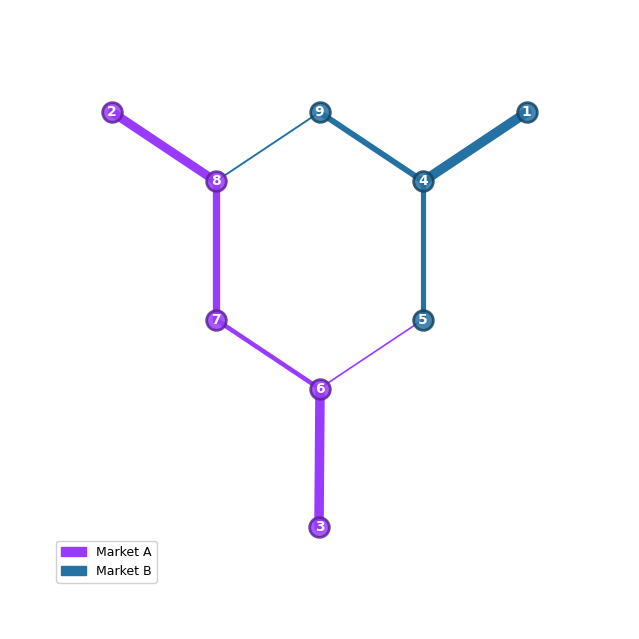

In [6]:
footprint_map()
plt.show()

### Slide 55: the case as configured

This figure carries only what is fixed about the case, and nothing in it is a clearing. Each line is labelled with its rating, and line 6-7's 40 MW is boxed in red. On the ring, each unit is its full capacity at its offer price, drawn solid, the three backstops included. Each load is drawn at its realized value and at the height of the highest offer, the backstop's \$55/MWh, so supply and demand share one price axis.

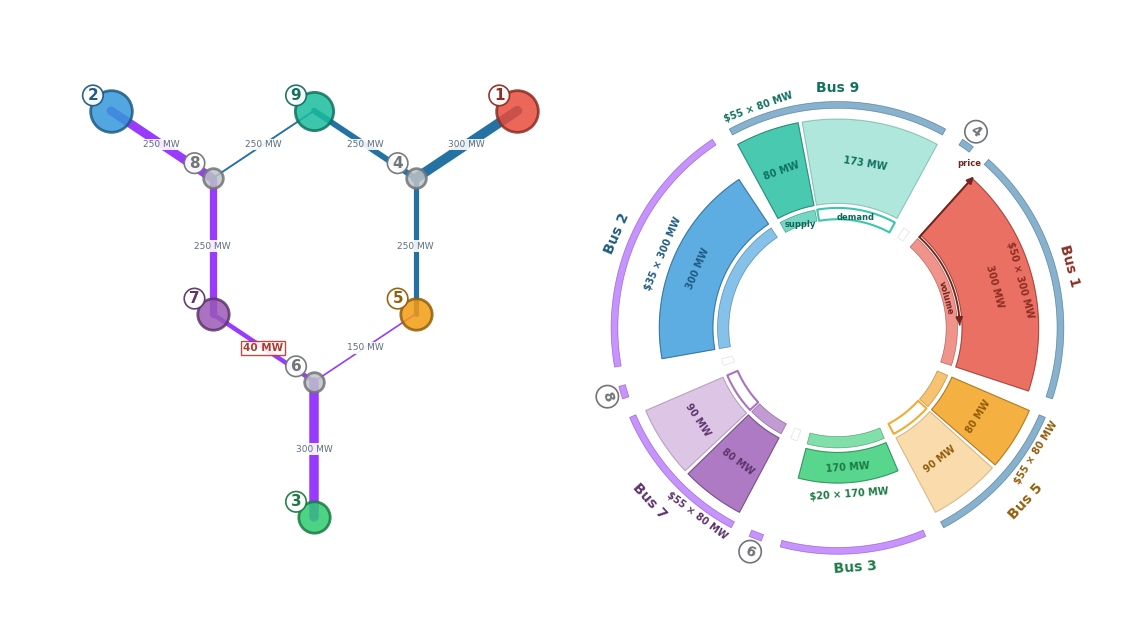

In [7]:
config_figure()
plt.show()

## Example 1: no forecast of the neighbor's flow contribution (slides 56 to 63)

Each market clears (1) with $\widehat F^{M'}=0$. Market A has a binding line, line 6-7, and finds its least-cost dispatch within the limit. Market B has no binding line, and line 6-7 is not in its monitored set $\mathcal M^B_{\mathrm{mon}}$. The superposed flow overloads line 6-7, and Market A then redispatches to bring it back within its rating.

### Slide 57: Market A clears

Market A clears (1) at the realized bus-7 load. Line 6-7 binds at its 40 MW rating, the \$35/MWh unit at bus 2 and the \$20/MWh unit at bus 3 are both interior, and the bus-7 LMP of \$37.1/MWh lies between their offers. The ring prices Market B's buses in gray at Market A's own LMPs from (3), and it draws the idle \$55/MWh backstop at bus 7. The production cost is \$2,535/h.

The settlement cell after the figure prints Market A's congestion rent by (5), \$804.1/h, as the settlement total and as the line total. The cell after it runs the base clearing, one engine over both footprints, and prints line 6-7's flow, its dual and the rent beside Market A's.

Market A: production cost $2,534.65/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 40.86 MW, gen_0 at bus 2 49.07 MW, backstop_7 at bus 7 0.00 MW

  line_4 (6-7): own flow +40.000 MW, input +0.000 MW, limit 40.000 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

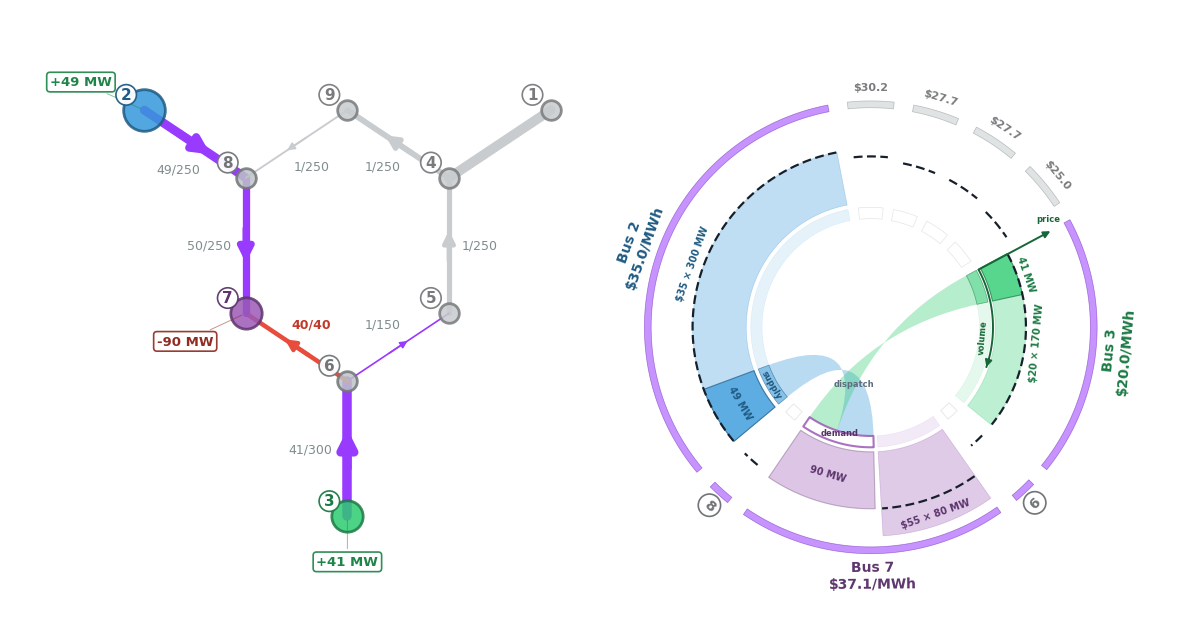

In [8]:
A1 = engine("Market A")
rA1 = clear(A1)
market_block(A1, rA1)
seam_views.own_view(net, pt, fp, "Market A", A1, rA1)
plt.show()

In [9]:
MU = abs(rA1.line_dual[STUDY_LINE])
C_HI = float(FLEET["gen_0"]["cost"])      # the interior pair's offers c_i
C_LO = float(FLEET["gen_1"]["cost"])
F_A1 = rA1.flow_own[STUDY_LINE]
SETTLE_A1 = settlement_by_bus(rA1, MARKETS["Market A"], A1.loads)
RENT_A1 = capacity_value_by_line(rA1, pt, A1.activated_lines)
print(SETTLE_A1.to_string())
print()
print(RENT_A1.to_string())
# (5) both ways: the settlement total and the line total, each rounded to $0.1/h by the
# library, and |mu| x |F^A| unrounded.
R_SETTLE = (SETTLE_A1.loc["SUBTOTAL", "paid by load ($/h)"]
            - SETTLE_A1.loc["SUBTOTAL", "paid to gen ($/h)"])
R_LINES = float(RENT_A1.loc["TOTAL", "rent |mu| x flow ($/h)"])
R_A1 = MU * abs(F_A1)
print(f"\n(5): settlement total ${R_SETTLE:,.1f}/h, line total ${R_LINES:,.1f}/h; "
      f"|mu| x |F^A| = {MU:.4f} x {abs(F_A1):.3f} = ${R_A1:,.3f}/h")

         LMP ($/MWh)  gen (MW)  paid to gen ($/h)  load (MW)  paid by load ($/h)
bus                                                                             
2               35.0      49.1             1717.4        0.0                 0.0
8               35.0       0.0                0.0        0.0                 0.0
7              37.13       0.0                0.0       89.9              3338.7
6               20.0       0.0                0.0        0.0                 0.0
3               20.0      40.9              817.2        0.0                 0.0
SUBTOTAL                  89.9             2534.6       89.9              3338.7

       from to flow (MW) rating (MW) binding |mu| ($/MWh = value of +1 MW)  rent |mu| x flow ($/h)
line                                                                                              
line_2    5  6      -0.9       150.0   False                           0.0                     0.0
line_3    3  6      40.9       300.0   False                           0.0                     0.0
line_4    6  7      40.0        40.0    True                          20.1                   804.1
line_5    7  8     -49.9       250.0   False                           0.0                     0.0
line_6    8  2     -49.1       250.0   False                           0.0                     0.0
TOTAL                                                                                        804.1


(5): settlement total $804.1/h, line total $804.1/h; |mu| x |F^A| = 20.1024 x 40.000 = $804.094/h

In [10]:
# The anchor: the base clearing, one engine over both footprints that enforces both
# activated sets, beside Market A's clear.
BASE = make_engine("base clearing", [b for bs in MARKETS.values() for b in bs],
                   gen_fleet=FLEET, loads=dict(LOADS),
                   activated=sorted(set().union(*map(set, ACTIVATED_LINES.values()))))
rBASE = clear(BASE)
market_block(BASE, rBASE)
SETTLE_BASE = settlement_by_bus(rBASE, list(pt.buses), BASE.loads)
BINDING_BASE = [m for m, v in rBASE.line_dual.items() if abs(v) > 1e-6]
PAIR = {name: sorted(g for g, v in r.dispatch.items() if 1e-6 < v < e.gens[g]["p_nom"] - 1e-6)
        for name, e, r in (("base clearing", BASE, rBASE), ("Market A", A1, rA1))}
ANCHOR = pd.DataFrame({
    "base clearing": [abs(rBASE.flow_own[STUDY_LINE]), abs(rBASE.line_dual[STUDY_LINE]),
                      SETTLE_BASE.loc["SUBTOTAL", "paid by load ($/h)"]
                      - SETTLE_BASE.loc["SUBTOTAL", "paid to gen ($/h)"],
                      sum(abs(rBASE.line_dual[m] * rBASE.flow_own[m])
                          for m in BASE.activated_lines)],
    "Market A": [abs(F_A1), MU, R_SETTLE, R_A1],
}, index=["|F| line 6-7 (MW)", "|mu| line 6-7 ($/MWh)", "R, settlement total ($/h)",
          "R, |mu| x |F| over the activated lines ($/h)"])
print(f"\nbinding lines in the base clearing: {BINDING_BASE}; interior units: {PAIR}")
print(ANCHOR.to_string(float_format=lambda v: f"{v:,.4f}"))

base clearing: production cost $10,021.10/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 155.59 MW, gen_0 at bus 2 197.41 MW, gen_slack_0 at bus 1 0.00 MW, backstop_5 at bus 5 0.00 MW, backstop_7 at bus 7 0.00 MW, backstop_9 at bus 9 0.00 MW

  line_4 (6-7): own flow +40.000 MW, input +0.000 MW, limit 40.000 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246


binding lines in the base clearing: ['line_4']; interior units: {'base clearing': ['gen_0', 'gen_1'], 'Market A': ['gen_0', 'gen_1']}

                                              base clearing  Market A
|F| line 6-7 (MW)                                   40.0000   40.0000
|mu| line 6-7 ($/MWh)                               20.1024   20.1024
R, settlement total ($/h)                          804.1000  804.1000
R, |mu| x |F| over the activated lines ($/h)       804.0945  804.0945

### Slide 58: the bus-7 price as a production-cost change

One more MW of load at bus 7 is served by raising the bus-2 unit and lowering the bus-3 unit in the proportions that hold line 6-7 at its rating, the first walk of (4). `seam_views.price_walk` solves the pair, and its cost is Market A's bus-7 LMP.

In [11]:
WALK_7, BIND_7 = seam_views.price_walk(pt, A1, rA1, "7")
print(seam_views.walk_text(WALK_7, "7", "Market A", rA1.lmp["7"], True, binding=BIND_7))

Market A -- bus 7, inside its footprint: the cost of one more MW of load

  gen_1 at bus 3: -0.1417 MW  x  $20.00/MWh           =  -$     2.83/h
  gen_0 at bus 2: +1.1417 MW  x  $35.00/MWh           =   $    39.96/h
  ------------------------------------------------------------------
  change in production cost                           =   $    37.13/h
  Market A's price at bus 7                           =   $    37.13/MWh   (binding: line_4)

### Slide 59: the line 6-7 shadow price as a production-cost change

One MW off line 6-7 raises the bus-2 unit and lowers the bus-3 unit by the same amount, $1/(SF_{3,m}-SF_{2,m})$ MW with $m$ line 6-7, the second walk of (4). Its cost is $\lvert\mu^A_m\rvert$, and the notebook-local `line_walk` solves it.

In [12]:
WALK_L = line_walk(A1, rA1, STUDY_LINE)
print(line_walk_text(WALK_L, STUDY_LINE, "Market A", rA1.line_dual[STUDY_LINE]))
print(f"\n1 / (SF[3] - SF[2]) = 1 / {SF['3'] - SF['2']:.5f} = {1.0 / (SF['3'] - SF['2']):.5f} MW")

Market A -- line 6-7 (line_4): the cost of one MW off the line

  gen_1 at bus 3: -1.3402 MW  x  $20.00/MWh           =  $   -26.80/h
  gen_0 at bus 2: +1.3402 MW  x  $35.00/MWh           =  $   +46.91/h
  ------------------------------------------------------------------
  change in production cost                           =  $   +20.10/h
  Market A |mu| on line_4                             =  $    20.10/MWh


1 / (SF[3] - SF[2]) = 1 / 0.74618 = 1.34016 MW

### Slide 60: Market B clears

Market B clears (1) at the realized bus-9 load. Its one unit, at bus 1, serves both its loads, no line in $\mathcal M^B_{\mathrm{act}}$ binds, and every LMP is the unit's \$50/MWh offer. By (2), Market B's dispatch places 9.4 MW on line 6-7. Market B neither monitors nor prices that line. The ring draws the idle backstops at buses 5 and 9.

Market B: production cost $13,153.49/h, energy price $50.000/MWh

  dispatch: gen_slack_0 at bus 1 263.07 MW, backstop_5 at bus 5 0.00 MW, backstop_9 at bus 9 0.00 MW

  line_4 (6-7): own flow +9.446 MW, input +0.000 MW, limit 40.000 MW, |mu| 0.0000 $/MWh, not in the activated set

  LMP ($/MWh): bus 1 50.000, bus 2 50.000, bus 3 50.000, bus 4 50.000, bus 5 50.000, bus 6 50.000, bus 7 50.000, bus 8 50.000, bus 9 50.000

line 6-7 in Market B's monitored set: False

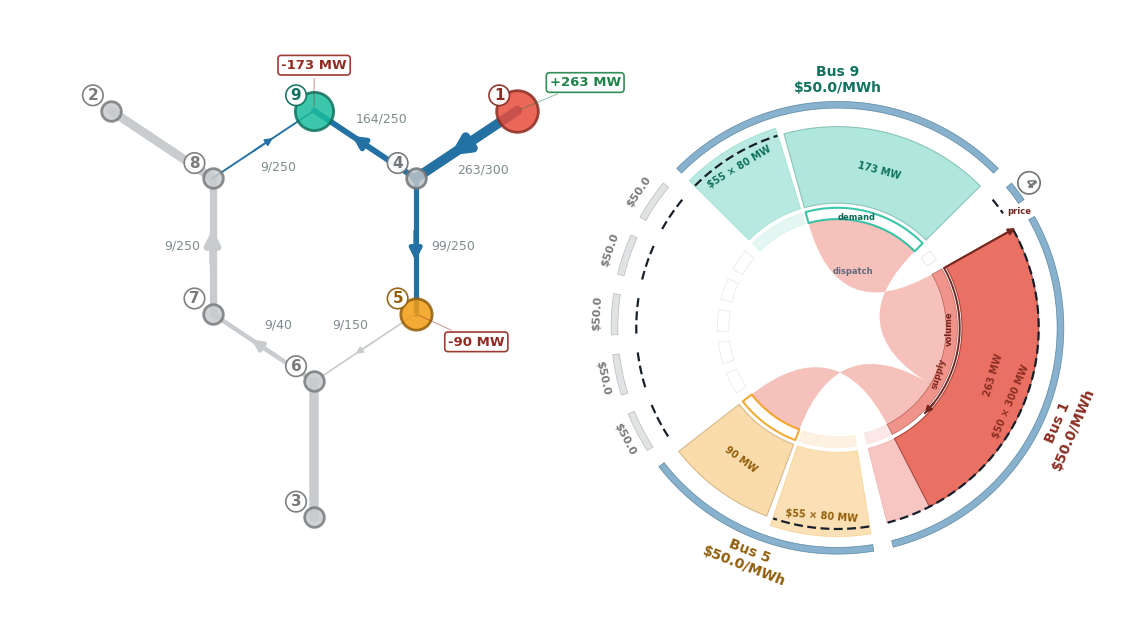

In [13]:
B = engine("Market B")
rB = clear(B)
FB = rB.flow_own[STUDY_LINE]
market_block(B, rB)
print(f"line 6-7 in Market B's monitored set: {STUDY_LINE in MONITORED_LINES['Market B']}")
seam_views.own_view(net, pt, fp, "Market B", B, rB)
plt.show()

### Slide 61: the superposed flow

By (2), line 6-7 carries Market A's 40.0 MW plus Market B's 9.4 MW, 49.4 MW against its 40 MW rating. `seam_views.combined_views` draws the superposition twice, as the combined letter and as the standalone network with each bus's combined net injection. Slide 61's right panel is the second figure, and its left thumbnails are slides 57 and 60.

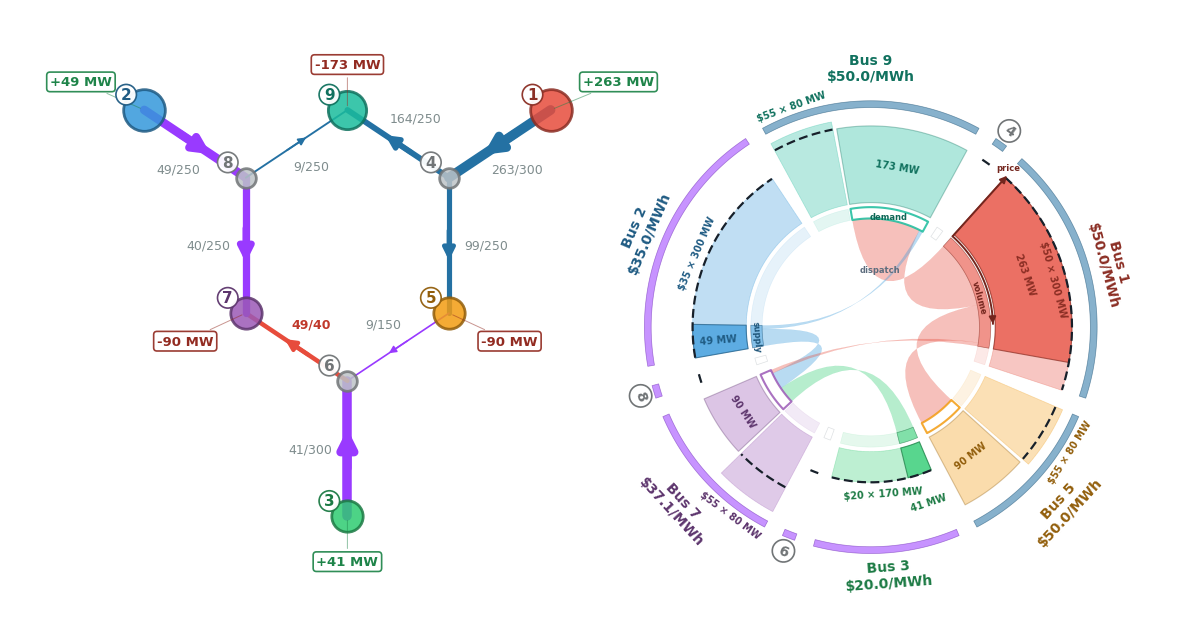

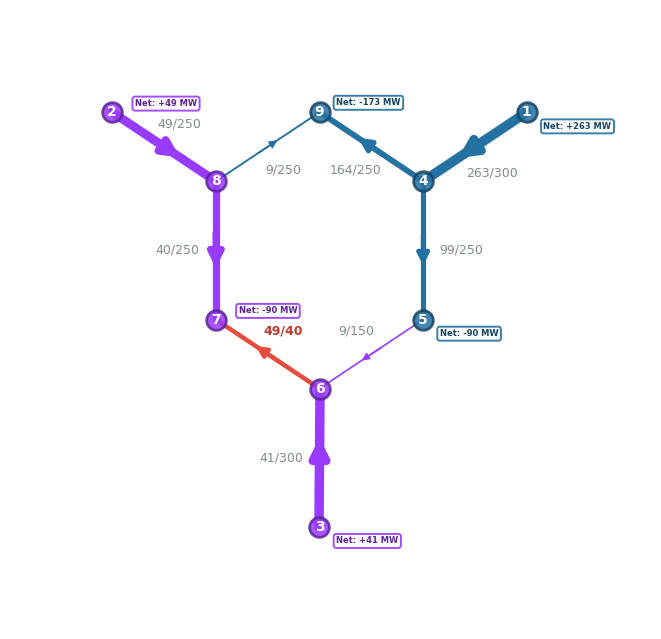

       from to  F[Market A]  F[Market B]    F^s  rating  loading_%  overload
line                                                                        
line_0    1  4          0.0        263.1  263.1   300.0       88.0     False
line_1    4  5         -0.9         99.4   98.6   250.0       39.0     False
line_2    5  6         -0.9          9.4    8.6   150.0        6.0     False
line_3    3  6         40.9         -0.0   40.9   300.0       14.0     False
line_4    6  7         40.0          9.4   49.4    40.0      124.0      True
line_5    7  8        -49.9          9.4  -40.5   250.0       16.0     False
line_6    8  2        -49.1          0.0  -49.1   250.0       20.0     False
line_7    8  9         -0.9          9.4    8.6   250.0        3.0     False
line_8    9  4         -0.9       -163.6 -164.5   250.0       66.0     False

In [14]:
PAIRS = [(A1, rA1), (B, rB)]
PF1 = seam_views.combined_views(net, pt, fp, PAIRS, "")
plt.show()
print(PF1.rename(columns={"F_phys": "F^s"}).to_string())
FS1 = superposed(rA1, rB)

### Slide 62: Market A redispatches to Market B's realized flow

Market A clears (1) again with $\widehat F^{B}$ set to Market B's realized flow on Market A's activated lines. The bus-2 unit rises and the bus-3 unit falls by 12.66 MW each, and Market A's production cost rises from \$2,535/h to \$2,725/h. By (6), the rise is Market B's 9.446 MW on line 6-7 times \$20.1024/MWh, \$189.89/h.

Slide 62 draws the blind superposition of slide 61, line 6-7 at 49/40, beside the redispatched cost. The figures below draw the redispatched superposition, line 6-7 at 40/40, which slide 63's reconciliation column shows.

Market A: production cost $2,724.54/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 28.20 MW, gen_0 at bus 2 61.73 MW, backstop_7 at bus 7 0.00 MW

  line_4 (6-7): own flow +30.554 MW, input +9.446 MW, limit 40.000 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

  change against the blind clear: gen_0 +12.6593 MW x $35 = $+443.08/h, gen_1 -12.6593 MW x $20 = $-253.19/h

  (6): $2,724.54 - $2,534.65 = $189.89/h; |mu| x F^B = 20.1024 x 9.44615 = $189.89/h

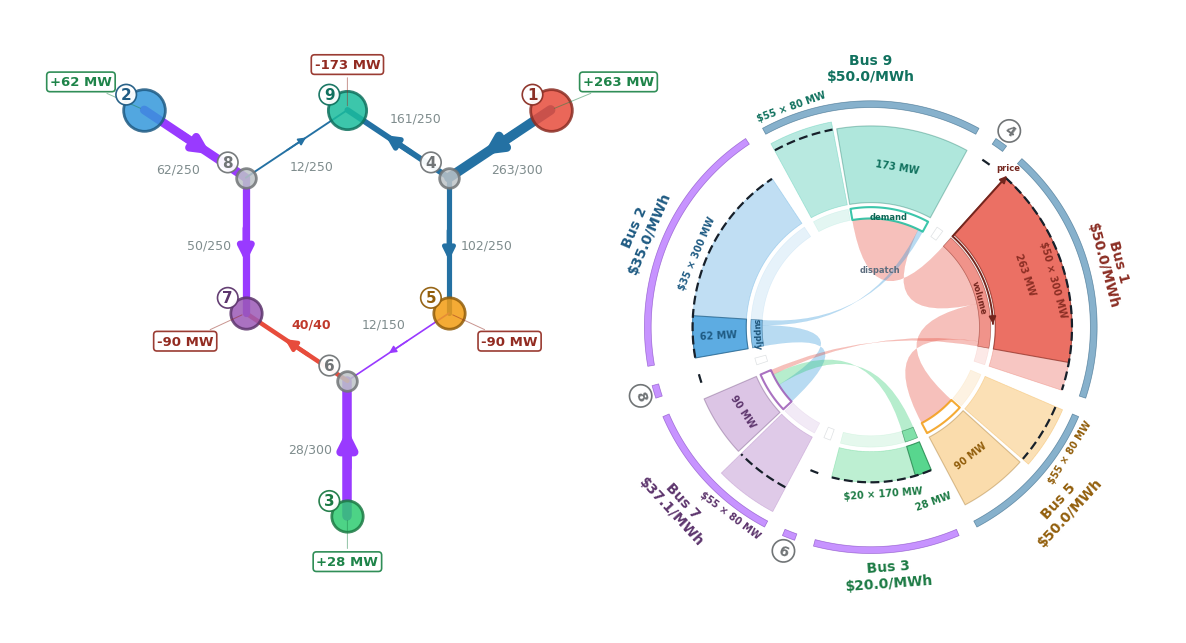

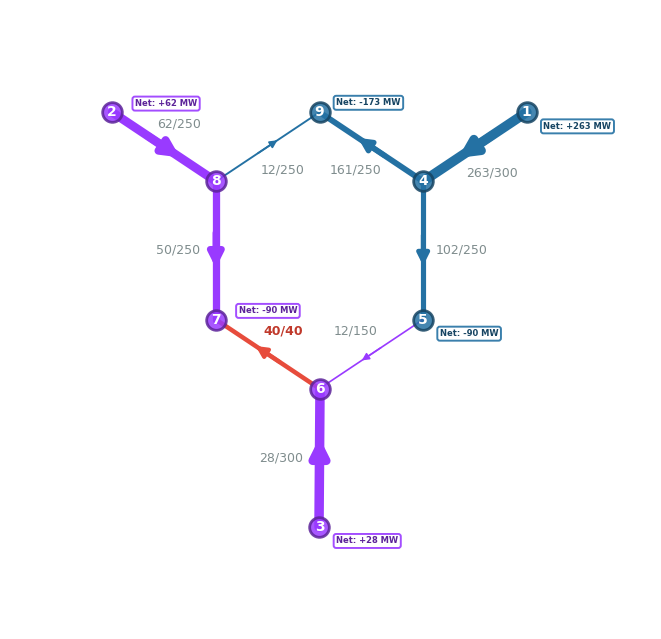

In [15]:
OFF_B = offsets_on(rB, A1)
A1r = engine("Market A")
rA1r = clear(A1r, OFF_B)
market_block(A1r, rA1r, OFF_B)
DG2_R = rA1r.dispatch["gen_0"] - rA1.dispatch["gen_0"]
DG3_R = rA1r.dispatch["gen_1"] - rA1.dispatch["gen_1"]
print(f"  change against the blind clear: "
      f"gen_0 {DG2_R:+.4f} MW x ${C_HI:g} = ${DG2_R * C_HI:+,.2f}/h, "
      f"gen_1 {DG3_R:+.4f} MW x ${C_LO:g} = ${DG3_R * C_LO:+,.2f}/h")
print(f"  (6): ${rA1r.total_cost:,.2f} - ${rA1.total_cost:,.2f} = "
      f"${rA1r.total_cost - rA1.total_cost:,.2f}/h; |mu| x F^B = {MU:.4f} x {FB:.5f} = "
      f"${MU * FB:,.2f}/h")
PF1R = seam_views.combined_views(net, pt, fp, [(A1r, rA1r), (B, rB)], "",
                                 binding=[STUDY_LINE])
plt.show()

In [16]:
FS1R = superposed(rA1r, rB)
LMP_MAX = max(max(r.lmp.values()) for r in (rA1, rB, rA1r))
print(f"highest LMP in the three clears ${LMP_MAX:.2f}/MWh, backstop ${BACKSTOP_PRICE:.0f}/MWh")
print(f"{STUDY_LINE} ({line_ends(STUDY_LINE)}) after the redispatch: F^s {FS1R[STUDY_LINE]:.4f} MW, "
      f"rating {RATE:.4f} MW, |F^s - rating| < {IDENTITY_TOL:g} MW: "
      f"{abs(FS1R[STUDY_LINE] - RATE) < IDENTITY_TOL}")

highest LMP in the three clears $50.00/MWh, backstop $55/MWh

line_4 (6-7) after the redispatch: F^s 40.0000 MW, rating 40.0000 MW, |F^s - rating| < 1e-09 MW: True

### Slide 63: the parallel process

Slide 63 shows Example 1 in three stages: inputs, optimization and reconciliation. The inputs are each market's capability, its load and the injections it assumes at the neighbor's buses, drawn below for Market A and then Market B. A blind clear carries no exogenous schedule and no flow input, so each neighbor bus reads 0 MW. The optimization is each market's clear, slides 57 and 60. The reconciliation column's second and third pictures are the redispatched superposition of the slide 62 cell. The column's first picture is the first reconciliation picture of the August deck (`caiso_spp_workshop_aug2026`, p. 108). It labels line 6-7 43/40 and prints net injections of +58 MW at bus 2 and +32 MW at bus 3. This notebook does not run that dispatch.

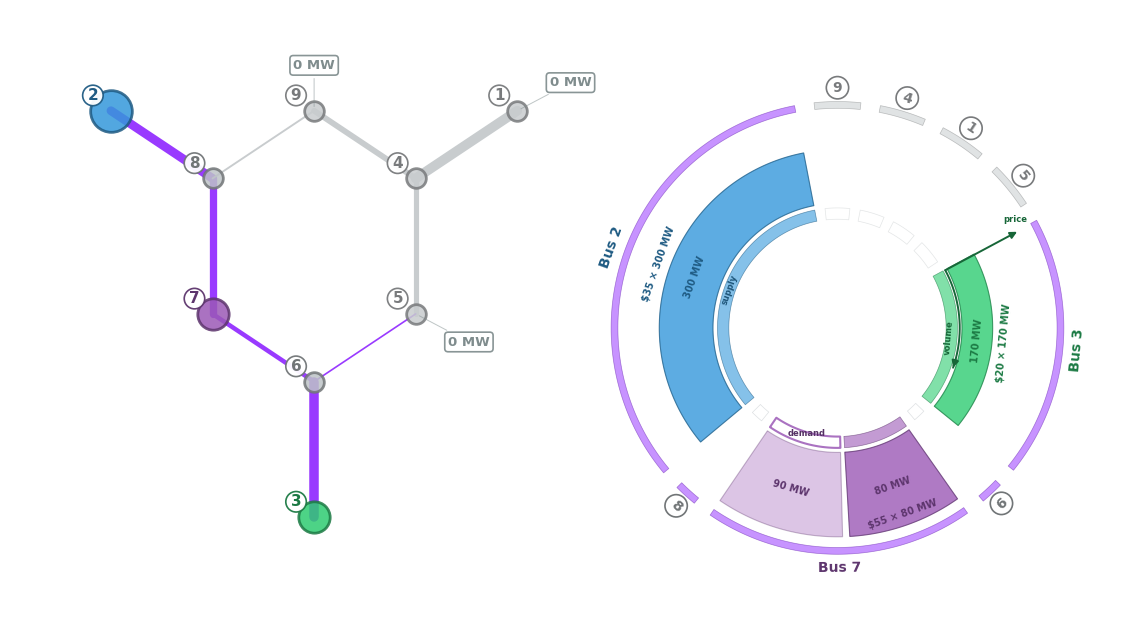

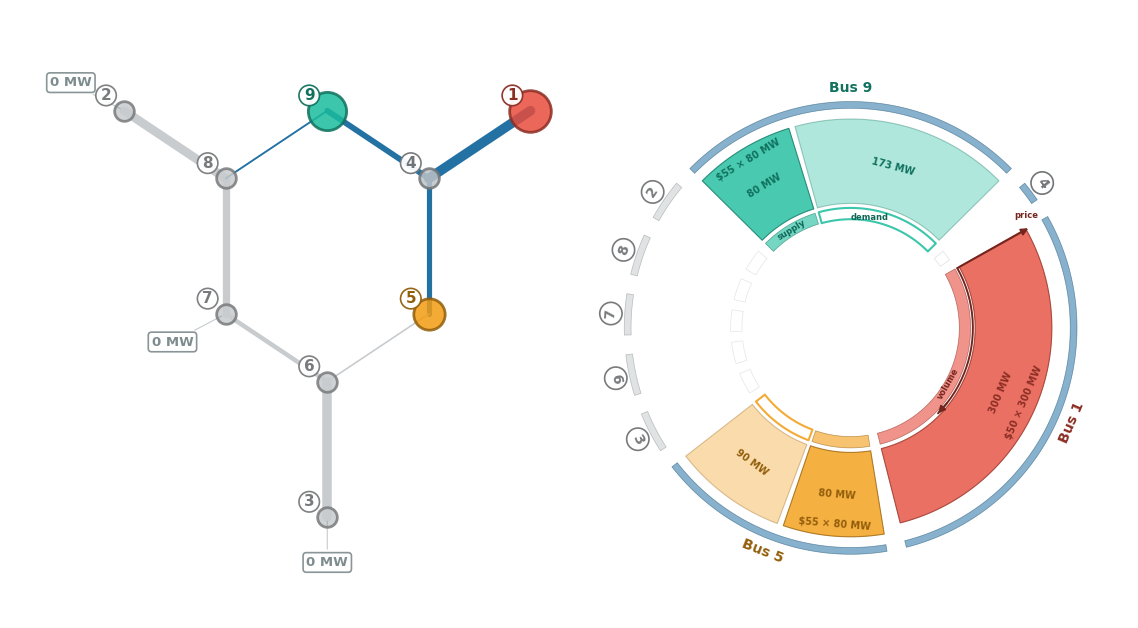

In [17]:
for _side, _eng, _res in (("Market A", A1, rA1), ("Market B", B, rB)):
    seam_views.market_inputs_view(net, pt, fp, _side, _eng,
                                  neighbor_mw=assumed_injections(_side, _res))
plt.show()

## Example 2: everything tagged (slides 64 to 71)

Example 2 starts from Example 1's blind dispatch and writes each market's dispatch as tags. The superposed flow overloads line 6-7, 49.4 MW against its 40 MW rating. The WLR process assigns the relief that brings line 6-7 within its rating by curtailing tagged schedules. Slides 65 to 69 carry the title *Example #1* for steps of Example 2, and they are headed under Example 2 here.

### Slide 65: the dispatch as tags

Market A's dispatch is two tags to the bus-7 load, A1 from the bus-3 unit (40.9 MW) and A2 from the bus-2 unit (49.1 MW). Market B's is two tags from the bus-1 unit, B1 to bus 5 (90.0 MW) and B2 to bus 9 (173.1 MW). The first table gives each tag's TDF and impact on line 6-7 by (7). The second gives each tag's flow on every line, which sums to the superposed flow by (8). The figure draws each tag as an arc, colored by its NERC priority code, over the blind superposed flow.

       market         unit source -> sink        MW priority  TDF line_4  impact line_4 (MW)
tag                                                                                         
A1   Market A        gen_1         3 -> 7   40.8603      7-F      0.8519             34.8105
A2   Market A        gen_0         2 -> 7   49.0697      7-F      0.1058              5.1895
B1   Market B  gen_slack_0         1 -> 5   90.0000      7-F     -0.1351            -12.1622
B2   Market B  gen_slack_0         1 -> 9  173.0699      7-F      0.1249             21.6083

           A1     A2     B1      B2  sum of tags     F^s
line_0   0.00   0.00  90.00  173.07       263.07  263.07
line_1  -6.05   5.19  77.84   21.61        98.59   98.59
line_2  -6.05   5.19 -12.16   21.61         8.59    8.59
line_3  40.86   0.00  -0.00   -0.00        40.86   40.86
line_4  34.81   5.19 -12.16   21.61        49.45   49.45
line_5  -6.05 -43.88 -12.16   21.61       -40.48  -40.48
line_6   0.00 -49.07   0.00    0.00       -49.07  -49.07
line_7  -6.05   5.19 -12.16   21.61         8.59    8.59
line_8  -6.05   5.19 -12.16 -151.46      -164.48 -164.48

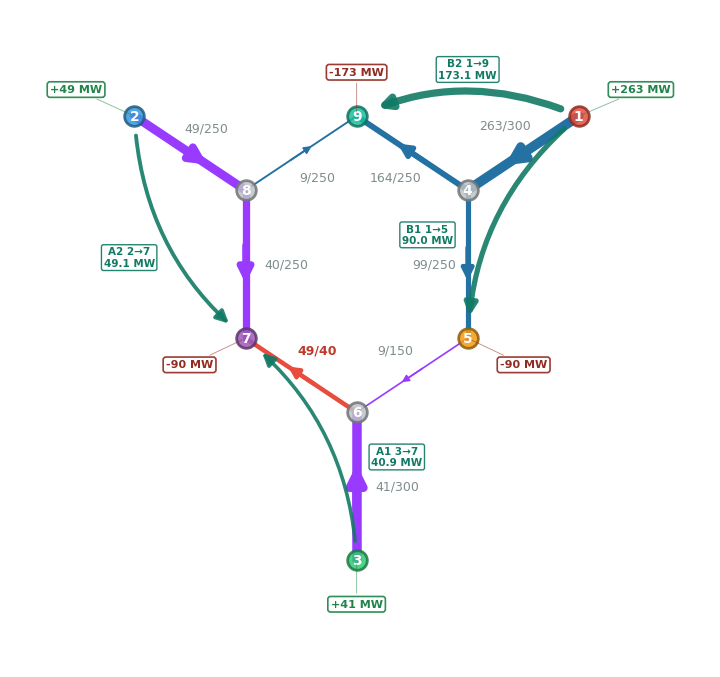

In [18]:
TAGS = (dispatch_tags(A1, rA1, TAG_PRIORITY["Market A"], "A")
        + dispatch_tags(B, rB, TAG_PRIORITY["Market B"], "B"))
UNIT_OF = {t.tag_id: u for t, u in TAGS}
TAG = {t.tag_id: t for t, _ in TAGS}
print(tag_table(TAGS).round(4).to_string())
FLOWS_TAGS = tag_flows(TAGS)
FLOWS_TAGS["sum of tags"] = FLOWS_TAGS.sum(axis=1)
FLOWS_TAGS["F^s"] = [FS1[m] for m in FLOWS_TAGS.index]
print()
print(FLOWS_TAGS.round(2).to_string())
tag_overlay(TAGS, FS1, net_mw=net_injection(rA1, rB))
plt.show()

In [19]:
# (8): each market's tags rebuild its flow contribution, and all tags the superposed flow.
_resid = (FLOWS_TAGS["sum of tags"] - FLOWS_TAGS["F^s"]).abs().max()
print(f"max |sum of tag flows - F^s| over every line < {IDENTITY_TOL:g} MW: "
      f"{_resid < IDENTITY_TOL}")
for _mkt, _r in (("Market A", rA1), ("Market B", rB)):
    _imp = sum(FLOWS_TAGS.loc[STUDY_LINE, t.tag_id] for t, _ in TAGS if t.gca == _mkt)
    print(f"{_mkt}: tags' impact on {STUDY_LINE} {_imp:+.3f} MW, "
          f"flow contribution {_r.flow_own[STUDY_LINE]:+.3f} MW")

max |sum of tag flows - F^s| over every line < 1e-09 MW: True

Market A: tags' impact on line_4 +40.000 MW, flow contribution +40.000 MW

Market B: tags' impact on line_4 +9.446 MW, flow contribution +9.446 MW

### Slide 66: tag A1, 3→7

The table is A1's physical path. Market A is its balancing authority (BA), transmission service provider (TSP) and scheduling entity (S/E). MO-A is its market operator and PSE-A its purchasing-selling entity. Its priority is 7-F. The panel is the flow A1 alone places on the network by (7). Line 6-7 is drawn orange where the tag loads it and blue where it counterflows it, and the box gives the tag's TDF, its impact and its eligibility by (10). A1's TDF on line 6-7 is +0.852 and its impact +34.8 MW, so it is eligible.

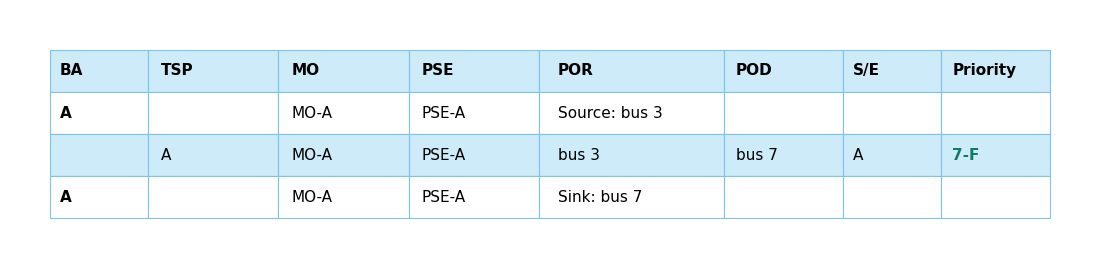

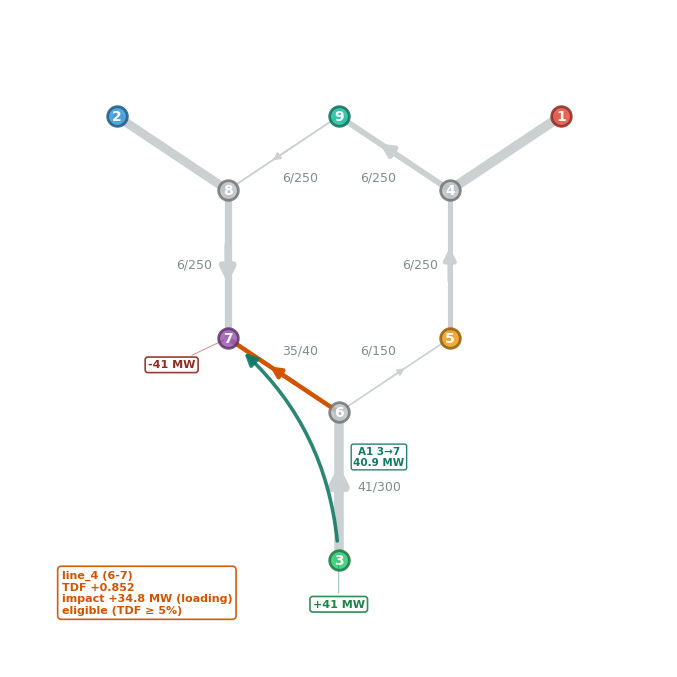

In [20]:
physical_path_figure(TAG["A1"], names=PATH_NAMES, mo=PATH_MO, title="")
plt.show()
_t = TAG["A1"]
_fig, _ = figs.induced_flow_panel(net, pt, _t.source, _t.sink, _t.mw, line=STUDY_LINE,
                                  tag_id=_t.tag_id, priority=_t.path[0].priority,
                                  threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 67: tag A2, 2→7

A2's TDF on line 6-7 is +0.106, above the 5 percent threshold, and its impact is +5.2 MW, so it is eligible.

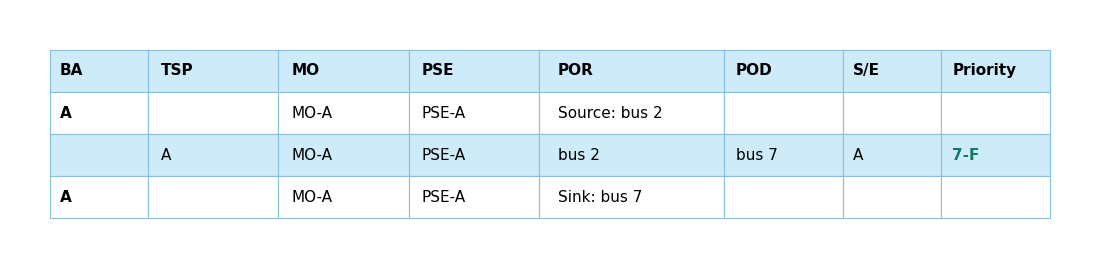

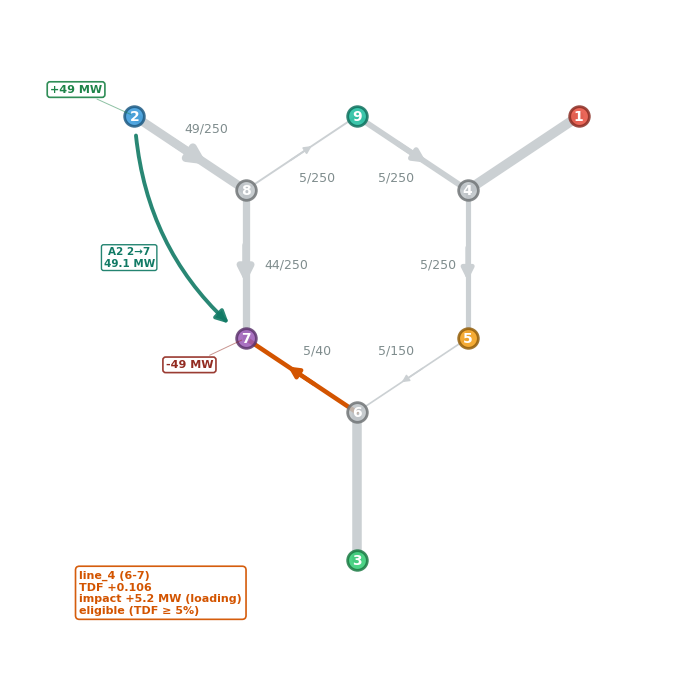

In [21]:
physical_path_figure(TAG["A2"], names=PATH_NAMES, mo=PATH_MO, title="")
plt.show()
_t = TAG["A2"]
_fig, _ = figs.induced_flow_panel(net, pt, _t.source, _t.sink, _t.mw, line=STUDY_LINE,
                                  tag_id=_t.tag_id, priority=_t.path[0].priority,
                                  threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 68: tag B1, 1→5

B1's sink, bus 5, has the larger shift factor on line 6-7, +0.135 against bus 1's 0, so B1's TDF is −0.135 and its impact −12.2 MW. B1 counterflows line 6-7, so its TDF is below the threshold in (10) and it is ineligible.

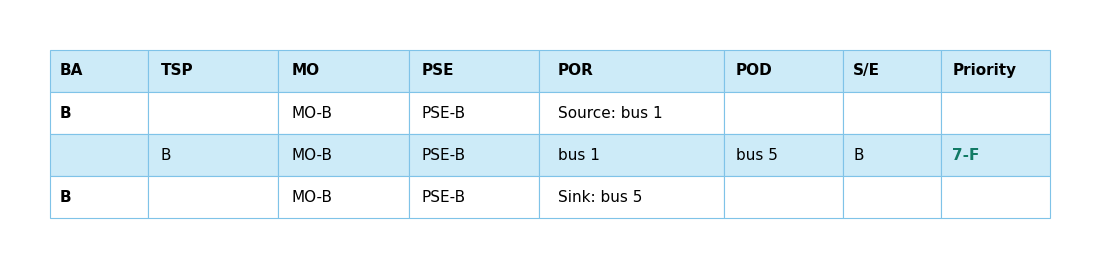

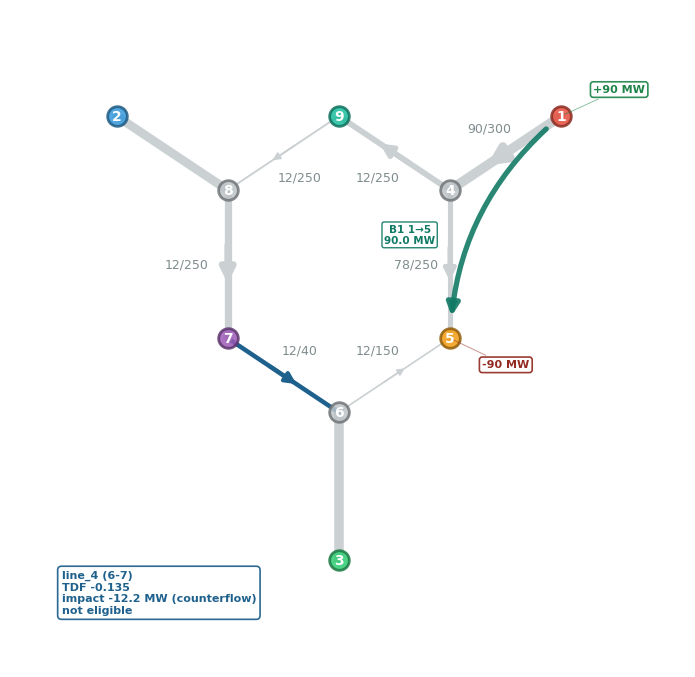

In [22]:
physical_path_figure(TAG["B1"], names=PATH_NAMES, mo=PATH_MO, title="")
plt.show()
_t = TAG["B1"]
_fig, _ = figs.induced_flow_panel(net, pt, _t.source, _t.sink, _t.mw, line=STUDY_LINE,
                                  tag_id=_t.tag_id, priority=_t.path[0].priority,
                                  threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 69: tag B2, 1→9

B2's TDF on line 6-7 is +0.125 and its impact +21.6 MW, so it is eligible.

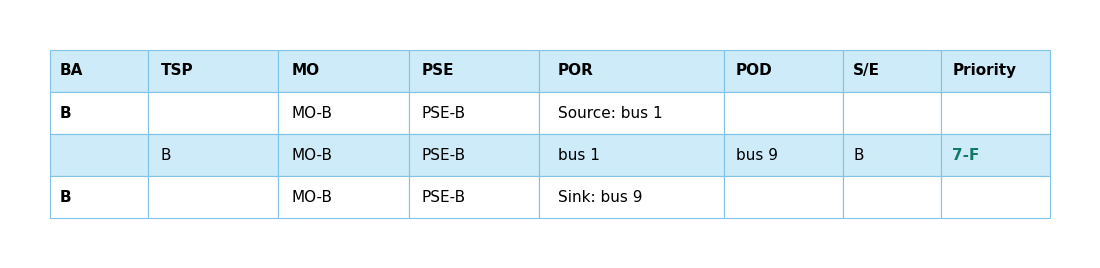

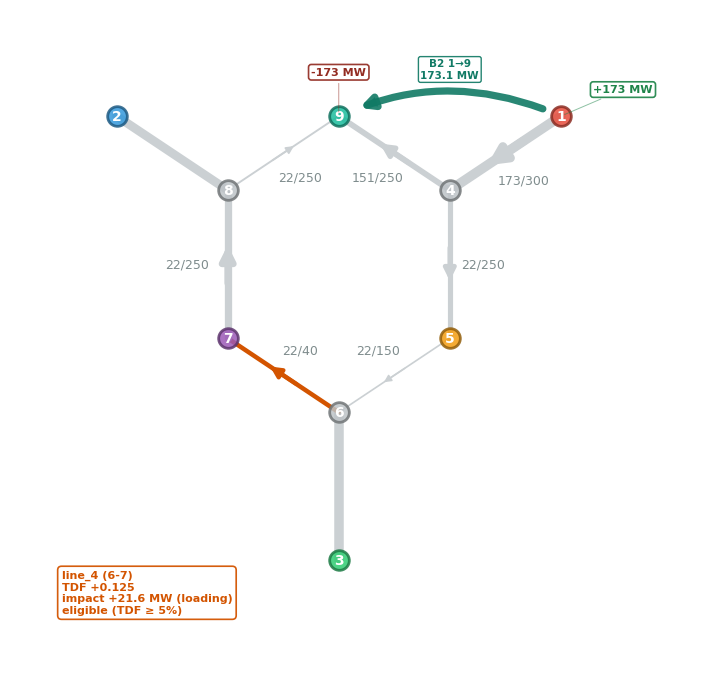

In [23]:
physical_path_figure(TAG["B2"], names=PATH_NAMES, mo=PATH_MO, title="")
plt.show()
_t = TAG["B2"]
_fig, _ = figs.induced_flow_panel(net, pt, _t.source, _t.sink, _t.mw, line=STUDY_LINE,
                                  tag_id=_t.tag_id, priority=_t.path[0].priority,
                                  threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 70: the calculation of relief

The relief requirement by (9) is the superposed flow of 49.446 MW less the 40 MW rating, 9.446 MW. A1, A2 and B2 are eligible at 7-F, the one priority level, and share the requirement in proportion to their impacts by (11). B1 is counterflow and takes no relief. Each tag's curtailment by (12) is its relief over its TDF. A2 has a TDF of 0.106, so 0.80 MW of relief curtails it 7.5 MW. Every eligible tag is curtailed by 15.3 percent of its megawatts. Market A's obligation is 6.13 MW and Market B's 3.31 MW.

This cell also computes the reconciliation (13), because the figure draws the tags over the reconciled flow, each tag's kept megawatts as a solid arc and its curtailment as a dashed one. The table prints the slide's layout.

(9): 49.4461 - 40.0 = 9.4461 MW; last priority level 7

                      Priority Scheduled (MW) Impact (MW) Share of relief Relief (MW) Curtailment or redispatch (MW) Curtailed to (MW)
Tag                                                                                                                                   
A1 (3→7)                   7-F           40.9        34.8           56.5%        5.34                            6.3              34.6
A2 (2→7)                   7-F           49.1         5.2            8.4%        0.80                            7.5              41.5
B2 (1→9)                   7-F          173.1        21.6           35.1%        3.31                           26.5             146.5
B1 (1→5, counterflow)      7-F           90.0       -12.2    not eligible        0.00                            0.0              90.0
Total                                   353.0        49.4          100.0%        9.45                           40.3             312.7


relief obligations (12): Market A 6.1330 MW, Market B 3.3131 MW

rho^A + rho^B = 9.4461 MW, Delta F = 9.4461 MW, |residual| < 1e-09 MW: True

curtailment / scheduled MW, each eligible tag: A1 0.1533, A2 0.1533, B2 0.1533

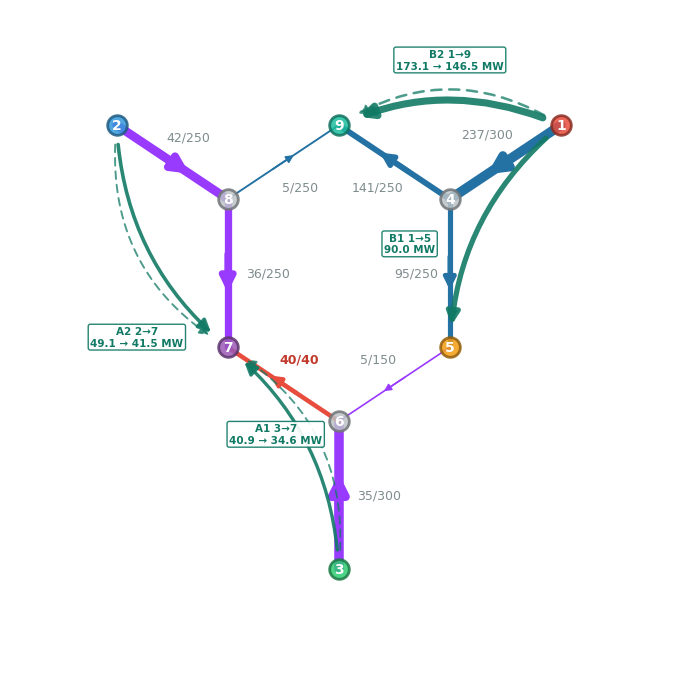

In [24]:
LED2 = wlr_ledger(tag_records(TAGS), FS1[STUDY_LINE])
OB2 = obligations(LED2)
EX2 = reconcile(PAIRS, tag_instructions(LED2, UNIT_OF))
FS2 = check_flows(EX2, "Example 2")
RT2 = relief_text(relief_table(LED2))
print(f"(9): {FS1[STUDY_LINE]:.4f} - {RATE:.1f} = {LED2.attrs['R']:.4f} MW; "
      f"last priority level {LED2.attrs['last_bucket']}")
print(RT2.to_string())
print("\nrelief obligations (12): " + ", ".join(f"{k} {v:.4f} MW" for k, v in OB2.items()))
print(f"rho^A + rho^B = {sum(OB2.values()):.4f} MW, Delta F = {LED2.attrs['R']:.4f} MW, "
      f"|residual| < {IDENTITY_TOL:g} MW: "
      f"{abs(sum(OB2.values()) - LED2.attrs['R']) < IDENTITY_TOL}")
_el = LED2[LED2["eligible"]]
print("curtailment / scheduled MW, each eligible tag: "
      + ", ".join(f"{k} {v:.4f}" for k, v in zip(_el["tag"], _el["cut"] / _el["MW"], strict=True)))
tag_overlay(TAGS, FS2, cut=dict(zip(LED2["tag"], LED2["instructed MW"], strict=True)))
plt.show()

### Slide 71: the resulting dispatch

Each curtailment comes off its tag's source unit and goes onto the backstop at its sink bus by (13). The bus-7 backstop takes A1's 6.3 MW and A2's 7.5 MW, 13.8 MW in all, and the bus-9 backstop takes B2's 26.5 MW. Line 6-7 carries 40.0 MW, and no line exceeds its rating. The ring reads each bus at the blind clear's price, so bus 9 reads \$50.0/MWh with the \$55/MWh backstop running.

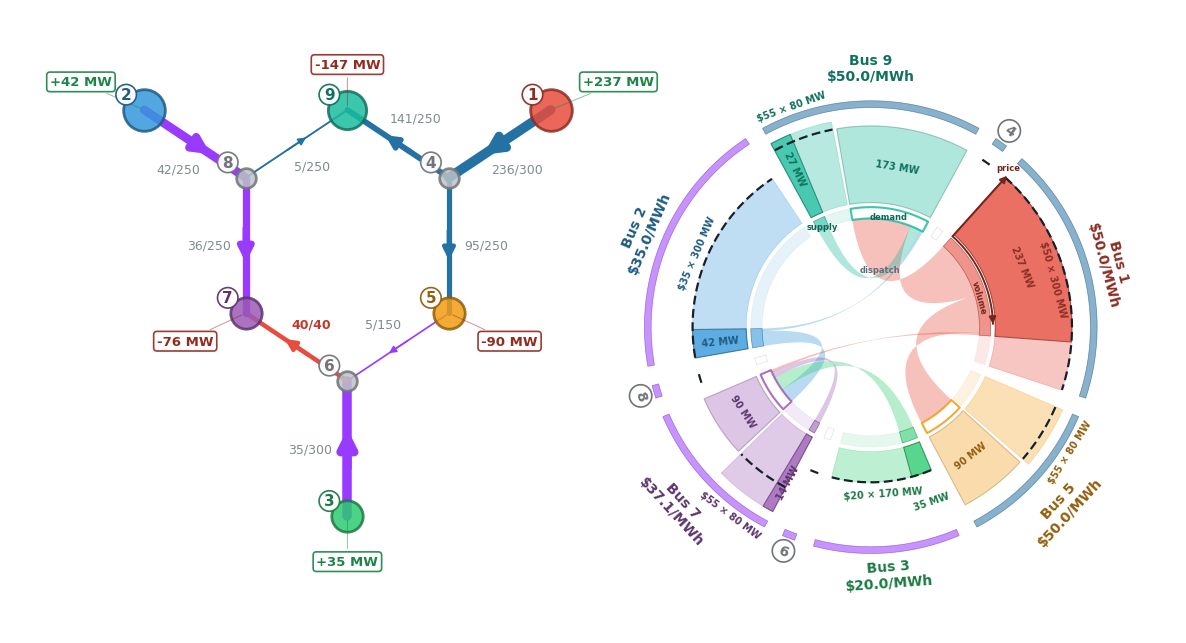

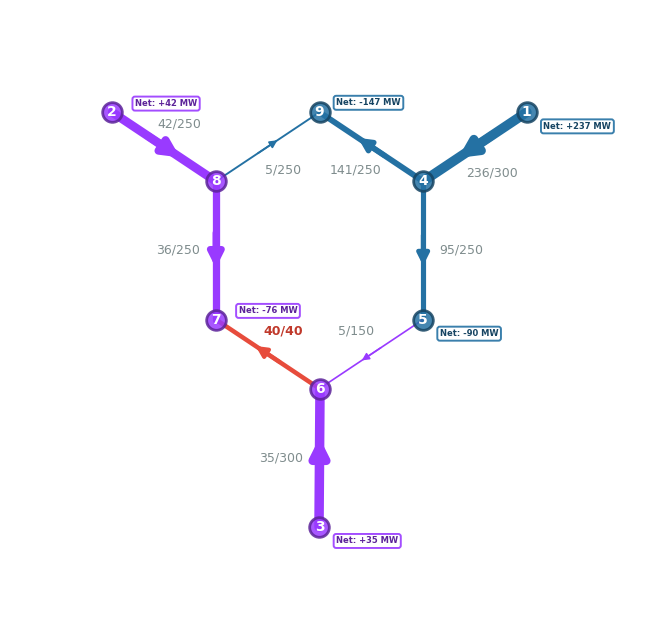

backstop dispatch (MW): bus 5 0.00 of 80, bus 7 13.79 of 80, bus 9 26.54 of 80

line_4 (6-7) after reconciliation: F^s 40.0000 MW, rating 40.0000 MW, |F^s - rating| < 1e-09 MW: True

In [25]:
PF2 = seam_views.combined_views(net, pt, fp, EX2, "", binding=[STUDY_LINE])
plt.show()
print("backstop dispatch (MW): " + ", ".join(
    f"bus {b} {v:.2f} of {BACKSTOP_MW[b]:.0f}" for b, v in backstop_mw(EX2).items()))
print(f"{STUDY_LINE} ({line_ends(STUDY_LINE)}) after reconciliation: F^s {FS2[STUDY_LINE]:.4f} MW, "
      f"rating {RATE:.4f} MW, |F^s - rating| < {IDENTITY_TOL:g} MW: "
      f"{abs(FS2[STUDY_LINE] - RATE) < IDENTITY_TOL}")
DISP2 = {g: mw for _, r in EX2 for g, mw in r.dispatch.items()}

## Example 3: tagged schedules and generation-to-load (slides 72 to 77)

Example 3 starts from Example 1's blind dispatch. Market A tags 25 MW of its 3→7 schedule as A1 and leaves the rest of its dispatch as untagged generation-to-load, and Market B keeps its two tags. The superposed flow overloads line 6-7, 49.4 MW against its 40 MW rating. The WLR process assigns the relief to the tags and to Market A's GTL.

### Slide 73: the tags

Market A's untagged generation is 15.9 MW at bus 3 and 49.1 MW at bus 2, and it serves 64.9 MW of the bus-7 load. The figure draws the three tags. The GTL has no source-to-sink schedule, so it has no arc.

Market A tagged: A1 3->7 25.00 MW

Market A untagged generation (MW): bus 3 15.86, bus 2 49.07; untagged load (MW): bus 7 64.93

untagged generation 64.9300 MW, untagged load 64.9300 MW, |residual| < 1e-09 MW: True

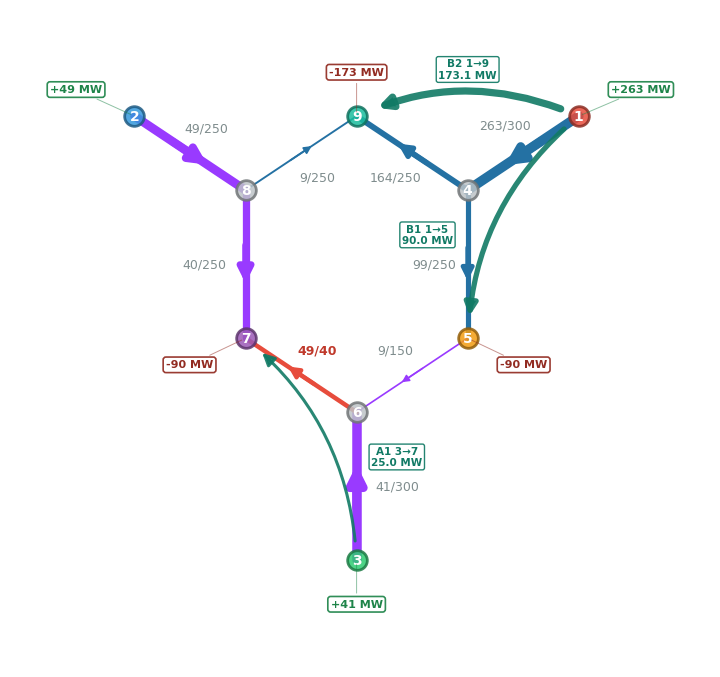

In [26]:
TAGS_A3, G_UN_A, D_UN_A, UNIT_AT_A = partial_tags(
    A1, rA1, {"A1": ("3", "7", A_TAG_MW)}, TAG_PRIORITY["Market A"])
TAGS3 = TAGS_A3 + [tu for tu in TAGS if tu[0].gca == "Market B"]
TAG3 = {t.tag_id: t for t, _ in TAGS3}
print("Market A tagged: " + ", ".join(f"{t.tag_id} {t.source}->{t.sink} {t.mw:.2f} MW"
                                       for t, _ in TAGS_A3))
print("Market A untagged generation (MW): "
      + ", ".join(f"bus {b} {v:.2f}" for b, v in G_UN_A.items())
      + "; untagged load (MW): " + ", ".join(f"bus {b} {v:.2f}" for b, v in D_UN_A.items()))
print(f"untagged generation {sum(G_UN_A.values()):.4f} MW, untagged load "
      f"{sum(D_UN_A.values()):.4f} MW, |residual| < {IDENTITY_TOL:g} MW: "
      f"{abs(sum(G_UN_A.values()) - sum(D_UN_A.values())) < IDENTITY_TOL}")
tag_overlay(TAGS3, FS1, net_mw=net_injection(rA1, rB))
plt.show()

### Slide 74: Market B's tagged schedules

Market B's tags are those of Example 2. B2 loads line 6-7 with +21.6 MW, and B1 counterflows it with −12.2 MW.

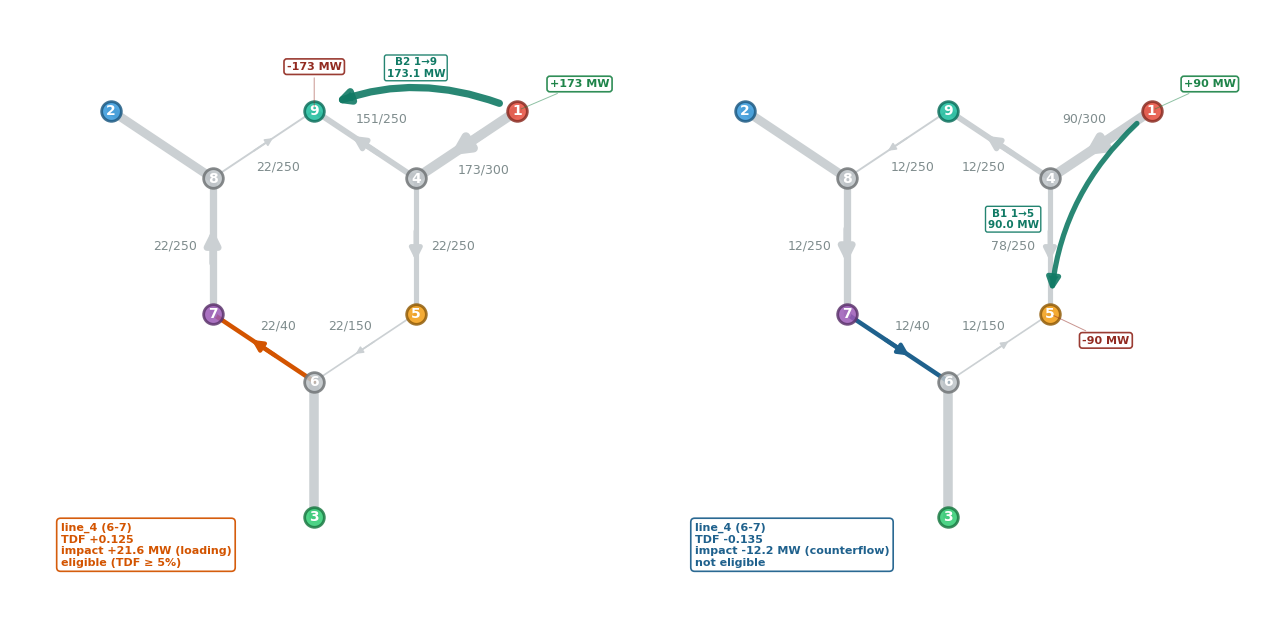

In [27]:
_fig, _axs = plt.subplots(1, 2, figsize=(15, 7.5))
for _ax, _tid in zip(_axs, ("B2", "B1"), strict=True):
    _t = TAG3[_tid]
    figs.induced_flow_panel(net, pt, _t.source, _t.sink, _t.mw, line=STUDY_LINE, ax=_ax,
                            tag_id=_t.tag_id, priority=_t.path[0].priority,
                            threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 75: Market A's tag and its generation-to-load

The left panel is A1 at 25 MW, with a TDF of +0.852 and an impact of +21.3 MW. The right panel is Market A's untagged net injections, +49.1 MW at bus 2, +15.9 MW at bus 3 and −64.9 MW at bus 7, and the flow they place by (14). Their impact on line 6-7 is +18.7 MW, which is +0.288 per injected megawatt, so the component is eligible.

(14): LSF -0.4671; impact +18.7015 MW; untagged generation 64.9300 MW; impact per injected MW +0.2880

      sum_n SF_n x_n = +18.7015 MW

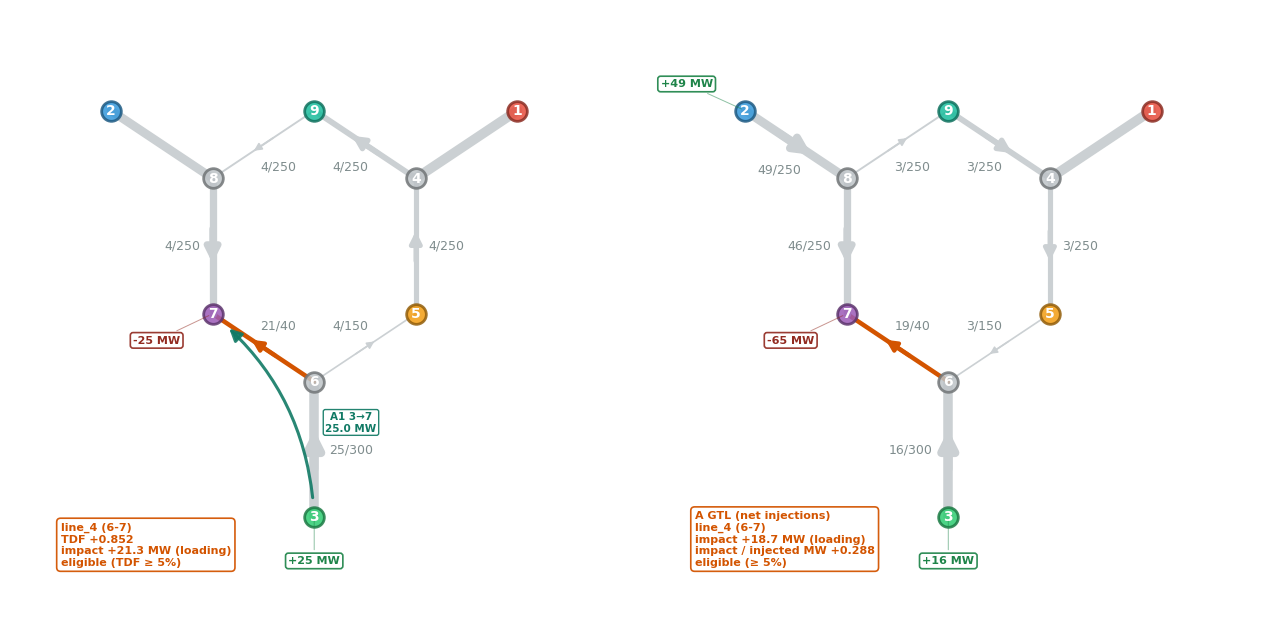

In [28]:
GTL_A = atc.wlr_gtl_component(pt, STUDY_LINE, G_UN_A, D_UN_A, market="Market A",
                              priority=GTL_PRIORITY, tag="A-GTL")
X_A = {b: G_UN_A.get(b, 0.0) - D_UN_A.get(b, 0.0) for b in pt.buses
       if b in G_UN_A or b in D_UN_A}
I_GTL = GTL_A["mw"] * GTL_A["tdf"]
print(f"(14): LSF {GTL_A['lsf']:+.4f}; impact {I_GTL:+.4f} MW; untagged generation "
      f"{GTL_A['mw']:.4f} MW; impact per injected MW {GTL_A['tdf']:+.4f}")
print(f"      sum_n SF_n x_n = {sum(SF[b] * v for b, v in X_A.items()):+.4f} MW")
A1_3 = TAG3["A1"]
FLOWS_A1_3 = tag_flows([(A1_3, None)])["A1"]
_fig, _axs = plt.subplots(1, 2, figsize=(15, 7.5))
figs.induced_flow_panel(net, pt, A1_3.source, A1_3.sink, A1_3.mw, line=STUDY_LINE,
                        ax=_axs[0], tag_id="A1", priority=A1_3.path[0].priority,
                        threshold=WLR_THRESHOLD)
figs.net_injection_flow_panel(net, pt, X_A, line=STUDY_LINE, ax=_axs[1],
                              label="A GTL (net injections)", threshold=WLR_THRESHOLD)
seam_views.strip(_fig)
plt.show()

### Slide 76: the calculation of relief

The requirement is 9.446 MW, as in Example 2. A1, Market A's GTL and B2 are eligible at 7-F and share it in proportion to their impacts by (11). A1 is curtailed 3.8 MW by (12). Market A's GTL obligation of 2.87 MW is allocated by (15). The bus-2 generator contributes 5.2 MW to the line at a generation-to-load distribution factor of 0.106. It takes 0.80 MW, an instruction of 7.5 MW. The bus-3 generator contributes 13.5 MW at 0.852. It takes 2.07 MW, an instruction of 2.4 MW. The two generator rows sit under the GTL row and outside the total. Each market's obligation is that of Example 2, 6.13 MW for Market A and 3.31 MW for Market B.

This cell also computes the reconciliation for the figure, which labels each bus's net injection after reconciliation to 0.1 MW.

                                 Priority Scheduled (MW) Impact (MW) Share of relief Relief (MW) Curtailment or redispatch (MW) Curtailed to (MW)
Tag                                                                                                                                              
A1 (3→7)                              7-F           25.0        21.3           34.6%        3.27                            3.8              21.2
A GTL (net injections), untagged      7-F           64.9        18.7           30.4%        2.87                           10.0              55.0
gen at bus 2                                        49.1         5.2            8.4%        0.80                            7.5              41.5
gen at bus 3                                        15.9        13.5           21.9%        2.07                            2.4              13.4
B2 (1→9)                              7-F          173.1        21.6           35.1%        3.31                           2


(15): Market A's GTL obligation 2.8674 MW over its untagged generators

          MW    GLDF  contribution  relief  instructed MW  MW after
bus                                                                
2    49.0697  0.1058        5.1895  0.7957         7.5237   41.5461
3    15.8603  0.8519       13.5120  2.0717         2.4318   13.4285


relief obligations (12): Market A 6.1330 MW, Market B 3.3131 MW

Example 3 less Example 2 (12): Market A 6.1330 against 6.1330, |difference| < 1e-09 MW: True, Market B 3.3131 against 3.3131, |difference| < 1e-09 MW: True

net injection after reconciliation (MW): bus 1 +236.53, bus 2 +41.55, bus 3 +34.60, bus 5 -90.00, bus 7 -76.14, bus 9 -146.53

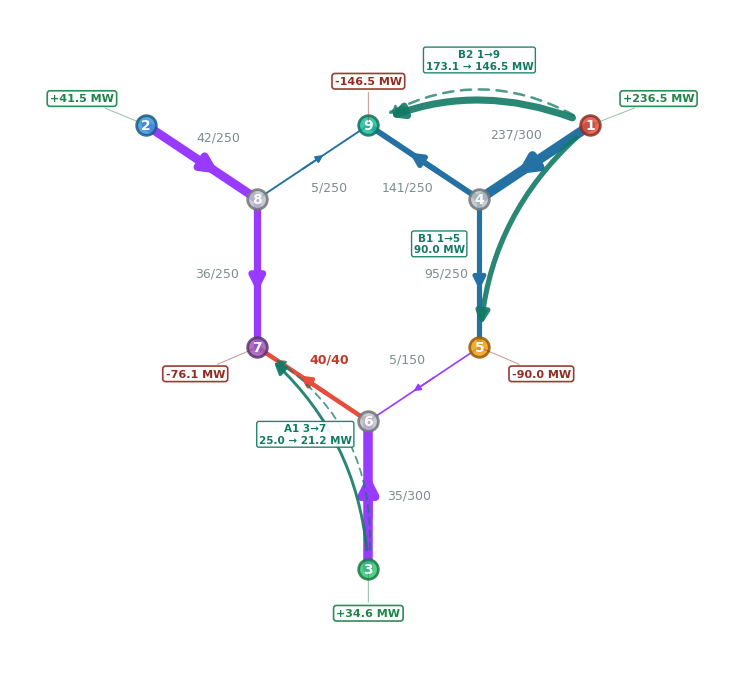

In [29]:
LED3 = wlr_ledger(tag_records(TAGS3) + [GTL_A], FS1[STUDY_LINE])
OB3 = obligations(LED3)
RHO_GTL_A = float(LED3.loc[LED3["kind"] == "GTL", "relief"].iloc[0])
GEN_A = gtl_generator_allocation(RHO_GTL_A, G_UN_A, D_UN_A, LED3.attrs["direction"])
assert len(D_UN_A) == 1, "the backstop instruction needs one untagged load bus"
LOAD_BUS_A = next(iter(D_UN_A))
INSTR3 = tag_instructions(LED3, {**UNIT_OF, **{t.tag_id: u for t, u in TAGS_A3}})
INSTR3 += [("Market A", UNIT_AT_A[b], LOAD_BUS_A, float(g["instructed MW"]))
           for b, g in GEN_A.iterrows() if g["instructed MW"] > 1e-12]
EX3 = reconcile(PAIRS, INSTR3)
FS3 = check_flows(EX3, "Example 3")
NET3 = net_injection(*(r for _, r in EX3))
RT3 = relief_text(relief_table(LED3, gen_alloc=GEN_A))
print(RT3.to_string())
print(f"\n(15): Market A's GTL obligation {RHO_GTL_A:.4f} MW over its untagged generators")
print(GEN_A.round(4).to_string())
print("\nrelief obligations (12): " + ", ".join(f"{k} {v:.4f} MW" for k, v in OB3.items()))
print("Example 3 less Example 2 (12): " + ", ".join(
    f"{k} {OB3[k]:.4f} against {OB2[k]:.4f}, |difference| < {IDENTITY_TOL:g} MW: "
    f"{abs(OB3[k] - OB2[k]) < IDENTITY_TOL}" for k in MARKETS))
print("net injection after reconciliation (MW): "
      + ", ".join(f"bus {b} {v:+.2f}" for b, v in NET3.items() if abs(v) > 1e-6))
tag_overlay(TAGS3, FS3, cut=dict(zip(LED3["tag"], LED3["instructed MW"], strict=True)),
            net_mw=NET3, net_mw_decimals=1)
plt.show()

### Slide 77: the resulting dispatch

Each tag's curtailment and each generator's instruction come off its unit and go onto the backstop at its load bus by (13). The bus-3 unit loses 3.8 MW on A1 and 2.4 MW on its untagged generation, 6.3 MW in all, its curtailment in Example 2. The bus-2 unit loses 7.5 MW, as A2 did. The dispatch equals Example 2's unit by unit, so slide 77 repeats slide 71's numbers.

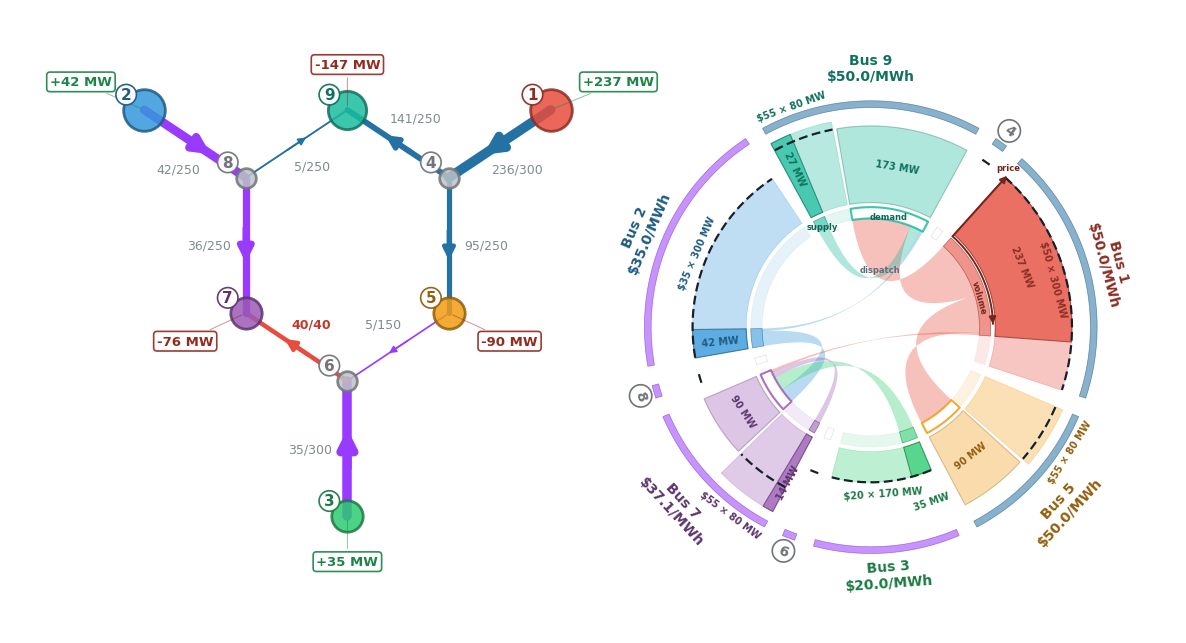

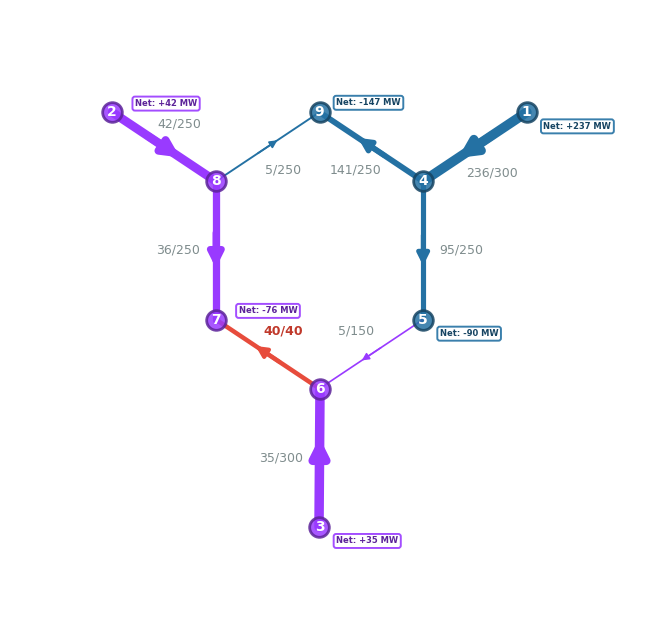

             Example 2 (MW)  Example 3 (MW)
gen_1               34.5954         34.5954
gen_0               41.5461         41.5461
backstop_7          13.7886         13.7886
gen_slack_0        236.5338        236.5338
backstop_5           0.0000          0.0000
backstop_9          26.5361         26.5361

units in Example 2 and not Example 3, or the reverse: []; max |Example 3 - Example 2| over the units < 1e-09 MW: True

line_4 (6-7) after reconciliation: F^s 40.0000 MW, rating 40.0000 MW, |F^s - rating| < 1e-09 MW: True

In [30]:
PF3 = seam_views.combined_views(net, pt, fp, EX3, "", binding=[STUDY_LINE])
plt.show()
DISP3 = {g: mw for _, r in EX3 for g, mw in r.dispatch.items()}
print(pd.DataFrame({"Example 2 (MW)": DISP2, "Example 3 (MW)": DISP3}).round(4).to_string())
print(f"units in Example 2 and not Example 3, or the reverse: "
      f"{sorted(set(DISP2) ^ set(DISP3))}; max |Example 3 - Example 2| over the units "
      f"< {IDENTITY_TOL:g} MW: "
      f"{max(abs(DISP3[g] - DISP2[g]) for g in DISP2) < IDENTITY_TOL}")
print(f"{STUDY_LINE} ({line_ends(STUDY_LINE)}) after reconciliation: F^s {FS3[STUDY_LINE]:.4f} MW, "
      f"rating {RATE:.4f} MW, |F^s - rating| < {IDENTITY_TOL:g} MW: "
      f"{abs(FS3[STUDY_LINE] - RATE) < IDENTITY_TOL}")

## Example 4: relief through each market's flow limit (slides 78 to 84)

Example 4 starts from Example 3's relief obligations, which slide 79 repeats from slide 76. Each obligation becomes a market flow limit (16) on line 6-7, and both markets clear (1) against their limits.

### Slide 80: Market A's market flow limit

Market A's components on line 6-7 are A1 and its GTL. Their impacts sum to its 40.0 MW flow contribution by (8), and their relief to its 6.13 MW obligation, so its limit is 33.9 MW. This cell runs Market A's clear against its limit, which the slide 82 cell prints, and the figure is that clear's inputs with line 6-7 rated at its limit.

                                 Priority Scheduled (MW) Impact (MW) Relief (MW)
Tag                                                                             
A1 (3→7)                              7-F           25.0        21.3        3.27
A GTL (net injections), untagged      7-F           64.9        18.7        2.87
Total                                               89.9        40.0         6.1
Market Flow Limit                                                           33.9


(16): sgn(F^s) F^A(0) - rho^A = +1 x 40.0000 - 6.1330 = 33.8670 MW

limit table 33.8670 MW, |residual| against (16) < 1e-09 MW: True

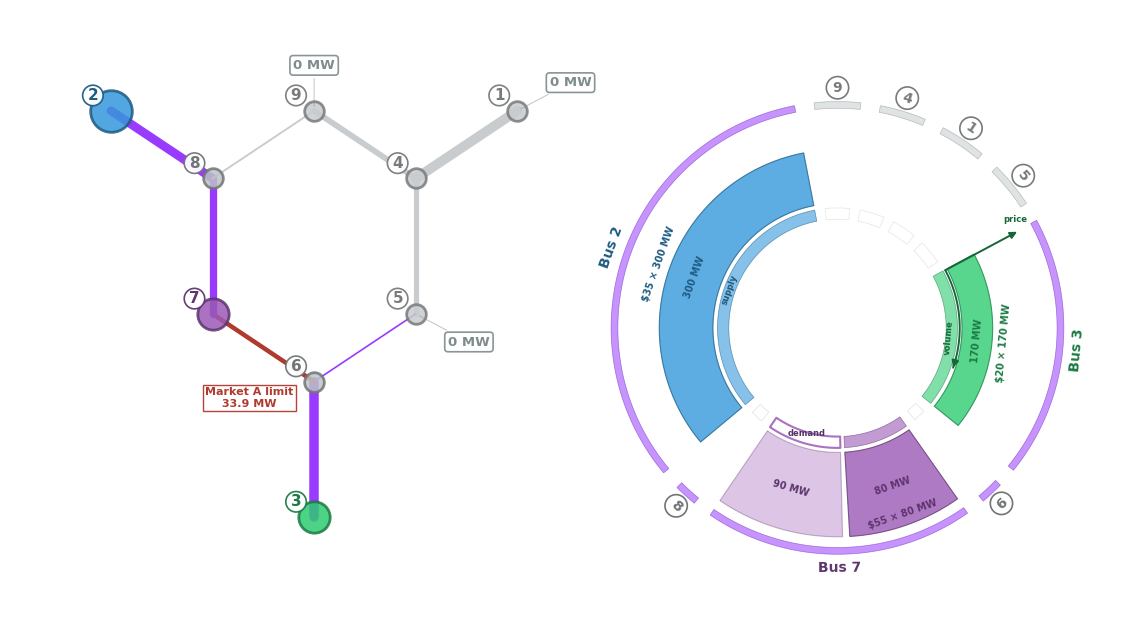

In [31]:
F0 = {"Market A": rA1.flow_own[STUDY_LINE], "Market B": rB.flow_own[STUDY_LINE]}
S_M = float(LED3.attrs["direction"])     # the loading direction, sgn F^s_m
LT_A, LIM_A = limit_table(LED3, "Market A")
print(LT_A.to_string())
print(f"\n(16): sgn(F^s) F^A(0) - rho^A = {S_M:+.0f} x {F0['Market A']:.4f} - "
      f"{OB3['Market A']:.4f} = {S_M * F0['Market A'] - OB3['Market A']:.4f} MW")
print(f"limit table {LIM_A:.4f} MW, |residual| against (16) < {IDENTITY_TOL:g} MW: "
      f"{abs(LIM_A - (S_M * F0['Market A'] - OB3['Market A'])) < IDENTITY_TOL}")
A4, rA4 = clear_capped("Market A", LIM_A)
limit_inputs_view("Market A", A4, rA4, LIM_A)
plt.show()

### Slide 81: Market B's market flow limit

Market B's impacts sum to its 9.4 MW flow contribution, 21.6 MW from B2 less 12.2 MW from B1, and its obligation is 3.31 MW, so its limit is 6.1 MW. The limit nets B1's counterflow, which takes no relief by (10). The two limits sum to the 40 MW rating. This cell runs Market B's clear against its limit, which the slide 83 cell prints, and the figure is that clear's inputs with line 6-7 rated at its limit.

                      Priority Scheduled (MW) Impact (MW) Relief (MW)
Tag                                                                  
B2 (1→9)                   7-F          173.1        21.6        3.31
B1 (1→5, counterflow)      7-F           90.0       -12.2        0.00
Total                                   263.1         9.4         3.3
Market Flow Limit                                                 6.1


(16): sgn(F^s) F^B(0) - rho^B = +1 x 9.4461 - 3.3131 = 6.1330 MW

limit table 6.1330 MW, |residual| against (16) < 1e-09 MW: True

limits A + B = 33.8670 + 6.1330 = 40.0000 MW

|limits A + B - rating 40.0 MW| < 1e-09 MW: True

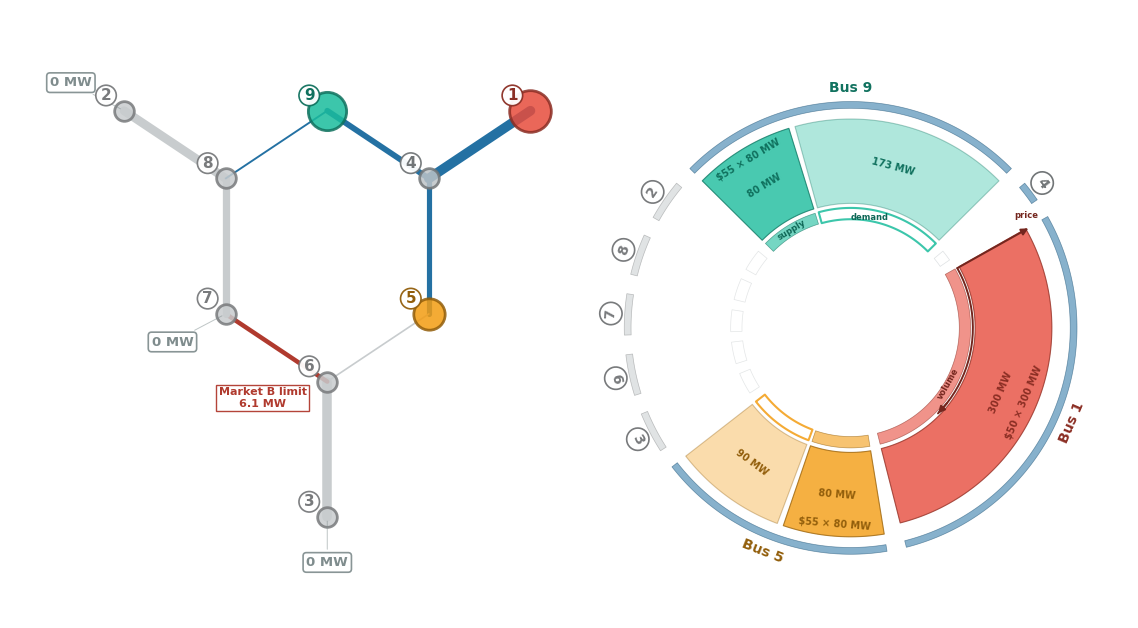

In [32]:
LT_B, LIM_B = limit_table(LED3, "Market B")
print(LT_B.to_string())
print(f"\n(16): sgn(F^s) F^B(0) - rho^B = {S_M:+.0f} x {F0['Market B']:.4f} - "
      f"{OB3['Market B']:.4f} = {S_M * F0['Market B'] - OB3['Market B']:.4f} MW")
print(f"limit table {LIM_B:.4f} MW, |residual| against (16) < {IDENTITY_TOL:g} MW: "
      f"{abs(LIM_B - (S_M * F0['Market B'] - OB3['Market B'])) < IDENTITY_TOL}")
print(f"limits A + B = {LIM_A:.4f} + {LIM_B:.4f} = {LIM_A + LIM_B:.4f} MW")
print(f"|limits A + B - rating {RATE:.1f} MW| < {IDENTITY_TOL:g} MW: "
      f"{abs(LIM_A + LIM_B - RATE) < IDENTITY_TOL}")
B4, rB4 = clear_capped("Market B", LIM_B)
limit_inputs_view("Market B", B4, rB4, LIM_B)
plt.show()

### Slide 82: Market A clears against its limit

Market A clears with its flow on line 6-7 held within 33.9 MW. The bus-2 unit rises to 57.3 MW and the bus-3 unit falls to 32.6 MW. The limit binds with $\lvert\mu^A_m\rvert=\$20.10$/MWh on the same interior pair as the blind clear, so every Market A LMP is unchanged.

Market A: production cost $2,657.94/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 32.64 MW, gen_0 at bus 2 57.29 MW, backstop_7 at bus 7 0.00 MW

  line_4 (6-7): own flow +33.867 MW, input +0.000 MW, limit 33.867 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

  change against the blind clear (MW): gen_1 -8.219, gen_0 +8.219, backstop_7 +0.000

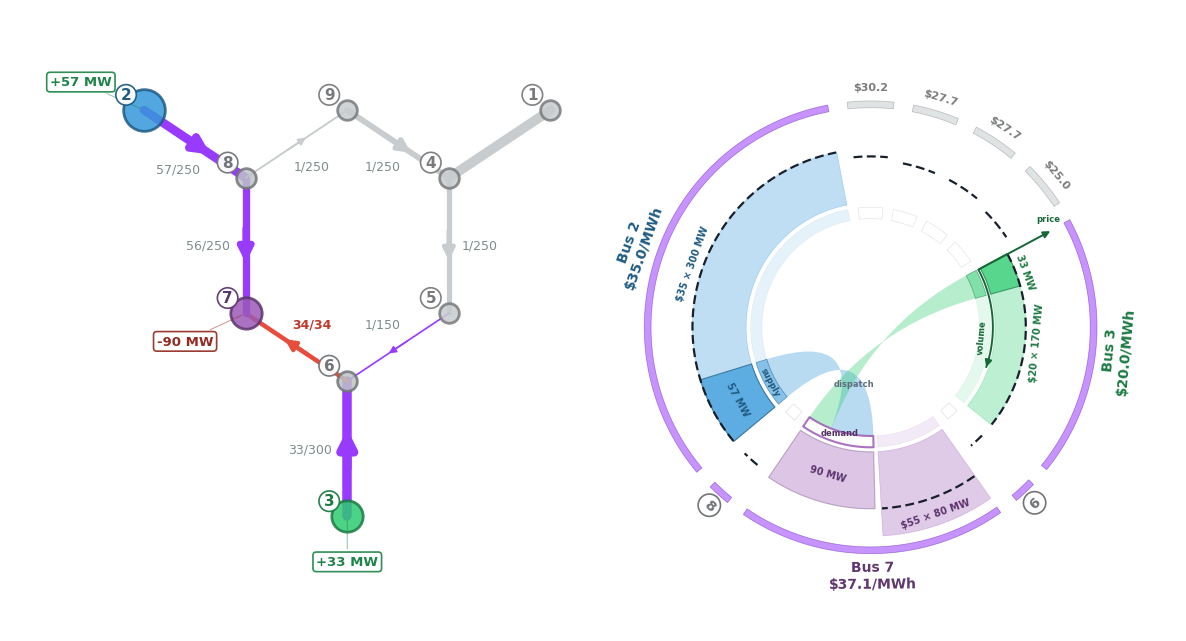

In [33]:
market_block(A4, rA4, rating=LIM_A)
print("  change against the blind clear (MW): " + ", ".join(
    f"{g} {rA4.dispatch[g] - rA1.dispatch[g]:+.3f}" for g in rA4.dispatch))
seam_views.own_view(net_with_rating(STUDY_LINE, LIM_A), pt, fp, "Market A", A4, rA4,
                    binding={STUDY_LINE})
plt.show()

### Slide 83: Market B clears against its limit

Market B clears with its flow on line 6-7 held within 6.1 MW. Among Market B's resources, only the bus-9 backstop lowers Market B's flow on line 6-7 when it runs in place of the bus-1 unit, so the bus-1 unit falls to 236.5 MW and the bus-9 backstop runs 26.5 MW. Line 6-7 enters Market B's monitored and activated sets for this clear. The limit binds with $\lvert\mu^B_m\rvert=\$40.05$/MWh. Bus 9's LMP is the backstop's \$55.0/MWh and bus 5's is \$44.6/MWh. The ring prices Market A's buses in gray at Market B's LMPs from (3).

Market B: production cost $13,286.17/h, energy price $50.000/MWh

  dispatch: gen_slack_0 at bus 1 236.53 MW, backstop_5 at bus 5 0.00 MW, backstop_9 at bus 9 26.54 MW

  line_4 (6-7): own flow +6.133 MW, input +0.000 MW, limit 6.133 MW, |mu| 40.0471 $/MWh

  LMP ($/MWh): bus 1 50.000, bus 2 64.471, bus 3 34.588, bus 4 50.000, bus 5 44.588, bus 6 34.588, bus 7 68.706, bus 8 64.471, bus 9 55.000

  change against the blind clear (MW): gen_slack_0 -26.536, backstop_5 +0.000, backstop_9 +26.536

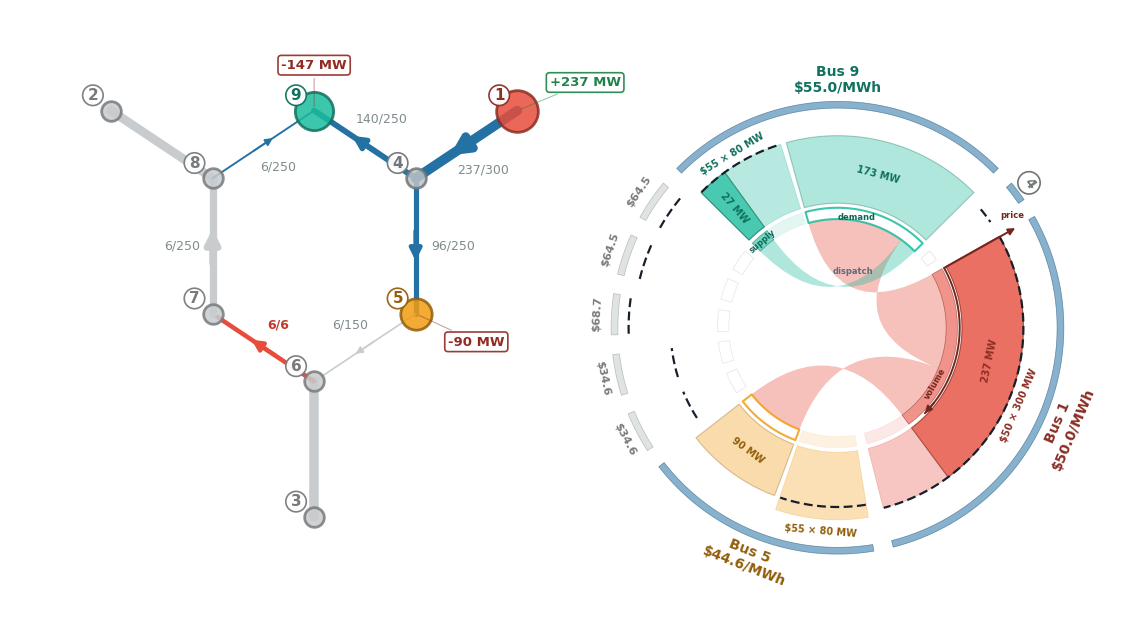

In [34]:
market_block(B4, rB4, rating=LIM_B)
print("  change against the blind clear (MW): " + ", ".join(
    f"{g} {rB4.dispatch[g] - rB.dispatch[g]:+.3f}" for g in rB4.dispatch))
seam_views.own_view(net_with_rating(STUDY_LINE, LIM_B), pt, fp, "Market B", B4, rB4,
                    binding={STUDY_LINE})
plt.show()

### Slide 84: the superposed flow

Line 6-7 carries Market A's 33.9 MW plus Market B's 6.1 MW, 40.0 MW, and no line exceeds its rating. The ring reads each bus at its own market's LMP.

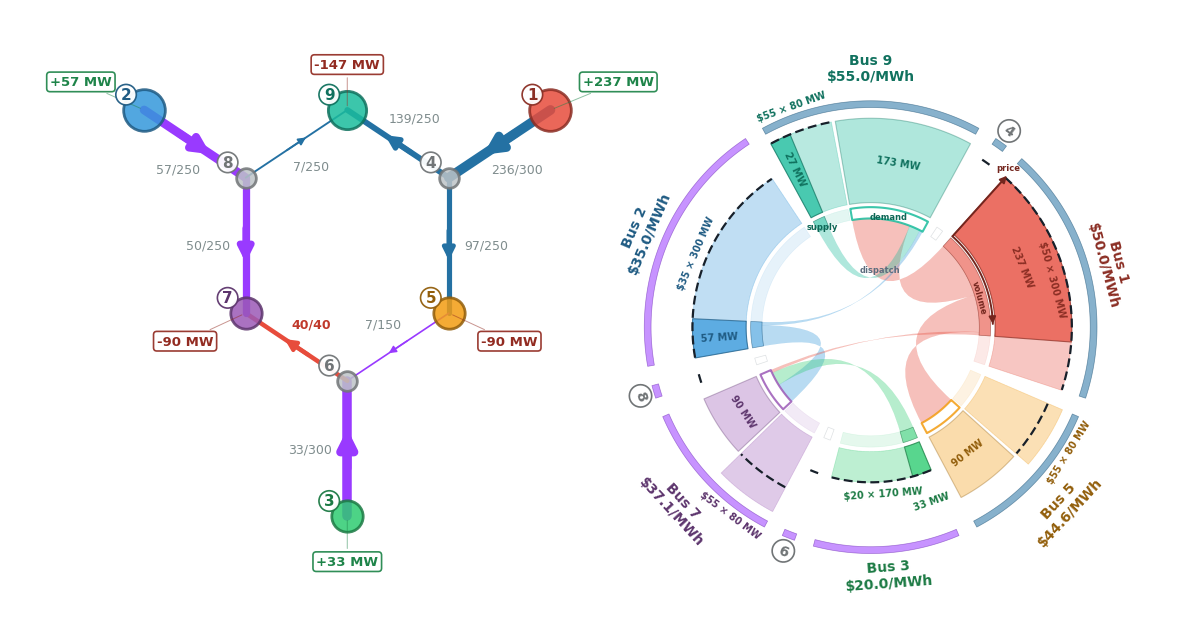

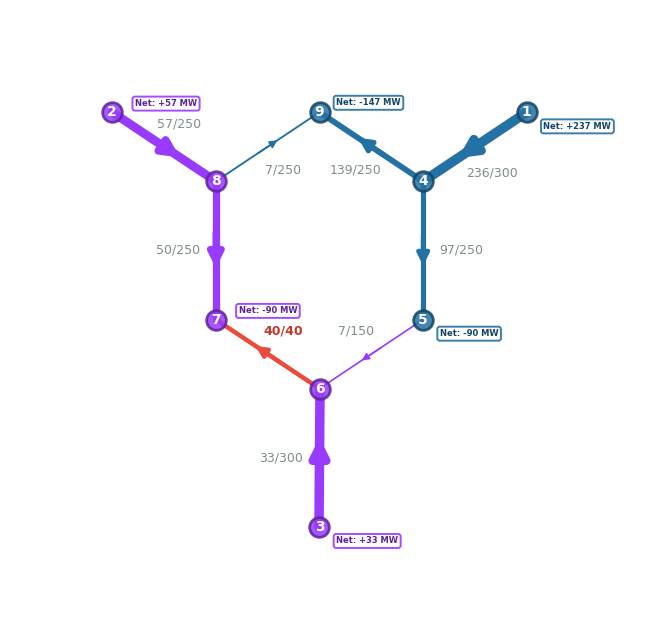

       from to  F[Market A]  F[Market B]    F^s  rating  loading_%  overload
line                                                                        
line_0    1  4          0.0        236.5  236.5   300.0       79.0     False
line_1    4  5          1.2         96.1   97.4   250.0       39.0     False
line_2    5  6          1.2          6.1    7.4   150.0        5.0     False
line_3    3  6         32.6         -0.0   32.6   300.0       11.0     False
line_4    6  7         33.9          6.1   40.0    40.0      100.0     False
line_5    7  8        -56.1          6.1  -49.9   250.0       20.0     False
line_6    8  2        -57.3          0.0  -57.3   250.0       23.0     False
line_7    8  9          1.2          6.1    7.4   250.0        3.0     False
line_8    9  4          1.2       -140.4 -139.2   250.0       56.0     False

In [35]:
PAIRS4 = [(A4, rA4), (B4, rB4)]
PF4 = seam_views.combined_views(net, pt, fp, PAIRS4, "", binding=[STUDY_LINE])
plt.show()
print(PF4.rename(columns={"F_phys": "F^s"}).to_string())
FS4 = check_flows(PAIRS4, "Example 4")

## Slides 85 and 86

Slide 85 repeats slide 63's inputs and optimization columns. Its reconciliation column is the August deck's first reconciliation picture, line 6-7 at 43/40, which this notebook does not run, then the superposition of slide 84. Slide 86 lists three elements of a framework for managing jointly impacted constraints, and it prints no number.

## Sandbox

The sandbox reruns the notebook's chain on the values in the EDIT cell: the blind clears, Market A's redispatch, Example 2's all-tagged assignment and reconciliation, Example 3's partly tagged assignment with the generator allocation, and Example 4's clears against the market flow limits. It prints the requirement, the host's cost change and the two limits. It returns one row per stage with the superposed flow on the study line, the two obligations and the backstop dispatch. The case cell after the EDIT cell builds the fleet, the loads, the shift factors and the footprints, so an edit takes effect when both cells are rerun before the cell below. A priority below 7-F on one market's tags puts those tags in a lower level of (11), which takes the relief first, up to its whole impact, before the other market's tags take any. Example 3's tag is fixed to the bus-3 unit, `gen_1`, and the bus-7 load. Where `A_TAG_MW` exceeds that unit's dispatch or that load, the chain tags the smaller of the dispatch and the load and prints the megawatts it used. The chain stops if Market A has more than one untagged load bus.

The notebook `101_sandbox.ipynb` clears the 9-bus case from one configuration cell, as one market or as two independent markets on the same network, and it carries the loading relief.

In [36]:
run_chain()

line_4 (6-7) rating 40.0 MW; blind superposed flow 49.446 MW; relief requirement 9.446 MW

host redispatch: Market A cost change +189.89 $/h

Example 4 limits: Market A 33.867 MW, Market B 6.133 MW

,F^s line_4 (MW),rho A (MW),rho B (MW),backstop bus 5 (MW),backstop bus 7 (MW),backstop bus 9 (MW)
stage,,,,,,
blind clears (Example 1),49.446,0.000,0.000,0.0,0.000,0.000
all tagged (Example 2),40.000,6.133,3.313,0.0,13.789,26.536
partly tagged (Example 3),40.000,6.133,3.313,0.0,13.789,26.536
market flow limits (Example 4),40.000,6.133,3.313,0.0,0.000,26.536
